## 1. Dataset import

In [6]:
import pandas as pd
import numpy as np

SEED = 42
np.random.seed(SEED)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

### Load the dataset in VS Code or Google Colab

The notebook first looks for the CSV in the project folder or current working directory. If it is not found locally and the notebook is running in Colab, it mounts Google Drive and uses the configured Drive path.


In [7]:
from pathlib import Path

CSV_NAME = "Copia di SEER Breast Cancer Dataset .csv"
PROJECT_DIR = Path(r"C:\Progetti\neuroengineering_course\progetto")
LOCAL_PATHS = [PROJECT_DIR / CSV_NAME, Path.cwd() / CSV_NAME]

# Prefer the local CSV when it is available, including in VS Code.
dataset_path = next((path for path in LOCAL_PATHS if path.is_file()), None)

if dataset_path is None:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise FileNotFoundError(
            "CSV not found locally. Place it in the project folder or update PROJECT_DIR."
        ) from exc

    # This branch runs in Colab when the CSV is not present locally.
    drive.mount("/content/drive")
    dataset_path = Path("/content/drive/MyDrive/progettoneuro") / CSV_NAME

if not dataset_path.is_file():
    raise FileNotFoundError(f"CSV not found at {dataset_path}. Check its location.")

print(f"Dataset path: {dataset_path}")


Dataset path: C:\Progetti\neuroengineering_course\progetto\Copia di SEER Breast Cancer Dataset .csv


In [8]:
# Read the dataset selected in the previous cell.
df = pd.read_csv(dataset_path)

print("Raw shape:", df.shape)
df.head()


Raw shape: (4024, 16)


,Age,Race,Marital Status,Unnamed: 3,T Stage,N Stage,6th Stage,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,43,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),NaN,T2,N3,IIIC,Moderately differentiated; Grade II,Regional,40,Positive,Positive,19,11,1,Alive
1,47,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),NaN,T2,N2,IIIA,Moderately differentiated; Grade II,Regional,45,Positive,Positive,25,9,2,Alive
2,67,White,Married (including common law),NaN,T2,N1,IIB,Poorly differentiated; Grade III,Regional,25,Positive,Positive,4,1,2,Dead
3,46,White,Divorced,NaN,T1,N1,IIA,Moderately differentiated; Grade II,Regional,19,Positive,Positive,26,1,2,Dead
4,63,White,Married (including common law),NaN,T2,N2,IIIA,Moderately differentiated; Grade II,Regional,35,Positive,Positive,21,5,3,Dead


The file contains two small technical artifacts that must be removed before any analysis (these are not part of the EDA you will do — they are defects of the CSV file, not of the clinical content):
- an unnamed, completely empty column;
- 1 duplicate row.

In [9]:
df = df.drop(columns=["Unnamed: 3"]).copy() #to remove empty colums
df.columns = [c.strip() for c in df.columns]  # removes accidental whitespace in column names
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after minimal cleaning:", df.shape)
assert df.isna().sum().sum() == 0, "there should be no missing values left" #there are no any missing value
df.head()

Shape after minimal cleaning: (4023, 15)


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status
0,43,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),T2,N3,IIIC,Moderately differentiated; Grade II,Regional,40,Positive,Positive,19,11,1,Alive
1,47,"Other (American Indian/AK Native, Asian/Pacifi...",Married (including common law),T2,N2,IIIA,Moderately differentiated; Grade II,Regional,45,Positive,Positive,25,9,2,Alive
2,67,White,Married (including common law),T2,N1,IIB,Poorly differentiated; Grade III,Regional,25,Positive,Positive,4,1,2,Dead
3,46,White,Divorced,T1,N1,IIA,Moderately differentiated; Grade II,Regional,19,Positive,Positive,26,1,2,Dead
4,63,White,Married (including common law),T2,N2,IIIA,Moderately differentiated; Grade II,Regional,35,Positive,Positive,21,5,3,Dead


### Data dictionary

| Column | Meaning |
|---|---|
| `Age` | Age at diagnosis (years) |
| `Race` | Ethnicity (SEER categories: White / Black / Other) |
| `Marital Status` | Marital status at diagnosis |
| `T Stage` | Extent of the primary tumor (AJCC), T1 (small) → T4 (extensive) |
| `N Stage` | Regional lymph node involvement, N1 → N3 (increasing) |
| `6th Stage` | Overall AJCC 6th edition stage (combines T, N, and metastatic status) |
| `Grade` | Histologic differentiation grade of the tumor (I = well differentiated → IV = anaplastic) |
| `A Stage` | Regional (localized/loco-regional) vs Distant (metastatic) |
| `Tumor Size` | Tumor diameter (mm) |
| `Estrogen Status` / `Progesterone Status` | Hormone receptor status (Positive/Negative) |
| `Regional Node Examined` | No. of lymph nodes surgically examined |
| `Reginol Node Positive` | No. of lymph nodes found positive (with metastasis) |
| `Survival Months` | Months of observed follow-up |
| `Status` | Status at the end of follow-up: Alive (alive/censored) or Dead (deceased) |

`Survival Months` and `Status` are **only** used to build the label — they are not legitimate model features (using them would be data leakage: they would use the very outcome you're trying to predict).

## 2. Label creation — 5-year Overall Survival

The task is: **predict whether a patient will have died within 5 years (60 months) of diagnosis**, using only clinico-pathological information available at diagnosis/initial staging.

Not all patients can be used: anyone still "Alive" with a shorter follow-up than 60 months is still under observation — their 5-year outcome is not known (censoring), and they must be excluded rather than forced into one of the two classes.

- **label = 1** (death within 5 years): `Status == "Dead"` and `Survival Months < 60`
- **label = 0** (survives to 5 years): `Survival Months >= 60` (regardless of what happens afterwards)
- **excluded**: `Status == "Alive"` and `Survival Months < 60` (unknown outcome)


In [10]:
HORIZON = 60  # months

survived = df[df["Survival Months"] >= HORIZON].copy()
survived["label"] = 0

died_early = df[(df["Status"] == "Dead") & (df["Survival Months"] < HORIZON)].copy()
died_early["label"] = 1

excluded = df[(df["Status"] == "Alive") & (df["Survival Months"] < HORIZON)]

task_df = pd.concat([survived, died_early], ignore_index=True)

print(f"Evaluable patients: {len(task_df)}  |  excluded (censored before 5 years): {len(excluded)} "
      f"({len(excluded)/len(df)*100:.1f}% of the original cohort)")
print(task_df["label"].value_counts(normalize=True).rename("share").round(3))

Evaluable patients: 3270  |  excluded (censored before 5 years): 753 (18.7% of the original cohort)
label
0    0.863
1    0.137
Name: share, dtype: float64


## 3. Train/test split and Cross-Validation

Stratified split (keeps the same proportion of events in train and test) with a fixed seed, so all groups start from the same data.

The columns `Survival Months`, `Status` (used to build the label) and the `label` itself are separated out from `X`. **`6th Stage` is not removed here**: it's one of the questions you should ask yourselves during EDA and feature engineering (hint: check its relationship with `T Stage`/`N Stage`/`A Stage`).


In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

LEAKAGE_COLS = ["Survival Months", "Status", "label"]  # Never use outcome information as a feature.
X = task_df.drop(columns=LEAKAGE_COLS).copy()
y = task_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Event prevalence (label=1) — train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))


Train: (2452, 13)  Test: (818, 13)
Event prevalence (label=1) — train: 0.137  test: 0.137


In [ ]:
# Cross-Validation to use for comparing models/hyperparameters ON THE TRAIN SET
# (never on the test set: that is reserved for final evaluation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

## 4. Feature Groups for the EDA

List the original numerical and categorical features so the exploratory analysis can use the appropriate summaries. The ordered variables are included among the categorical features at this stage. No scaling or encoding is fitted here.


In [ ]:
NUM_COLS = ["Age", "Tumor Size", "Regional Node Examined", "Reginol Node Positive"]
ORD_COLS = ["T Stage", "N Stage", "Grade"]  # These categories have a meaningful clinical order.
CAT_COLS = ["Race", "Marital Status", "6th Stage", "A Stage",
            "Estrogen Status", "Progesterone Status"]
assert set(NUM_COLS) | set(ORD_COLS) | set(CAT_COLS) == set(X_train.columns)


## Project Checklist

The following sections explore the original training features, examine their relationships, and then create the Positive Node Ratio and define the model preprocessor. Model development, evaluation and FUTURE-AI assessment remain to be completed.


## 5. Exploratory Data Analysis (EDA)

This section describes the training set before model development. Class **0** means observed survival of at least 60 months; class **1** means death from any cause before 60 months. Patients recorded alive with shorter follow-up were excluded because their five-year outcome is unknown. This exclusion may affect how representative the analyzed cohort is.

All comparisons below use `X_train` and `y_train`; the held-out test set remains reserved for final model evaluation. Group differences are descriptive associations, not evidence of causation.


In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display
import textwrap

# Keep the outcome aligned with its original training-set rows.
assert X_train.index.equals(y_train.index)
eda_train = X_train.copy()
eda_train["label"] = y_train

# Reuse the feature groups defined in the preprocessing section.
EDA_NUM_COLS = NUM_COLS
EDA_CAT_COLS = ORD_COLS + CAT_COLS
assert set(EDA_NUM_COLS + EDA_CAT_COLS) == set(X_train.columns)

print(f"Cleaned cohort: {len(df):,} patients")
print(f"Excluded because of censoring before 5 years: {len(excluded):,}")
print(f"Evaluable cohort: {len(task_df):,} patients")
print(f"Training set analyzed below: {len(eda_train):,} patients")


Cleaned cohort: 4,023 patients
Excluded because of censoring before 5 years: 753
Evaluable cohort: 3,270 patients
Training set analyzed below: 2,452 patients


### 5.1 Outcome Distribution

The classes are imbalanced. The table and chart show how many training patients are in each outcome group. The positive class is death before five years. This information helps us interpret later comparisons and select evaluation metrics.


,Patients,Training set (%)
0: Survived at least 5 years,2115,86.3
1: Died before 5 years,337,13.7


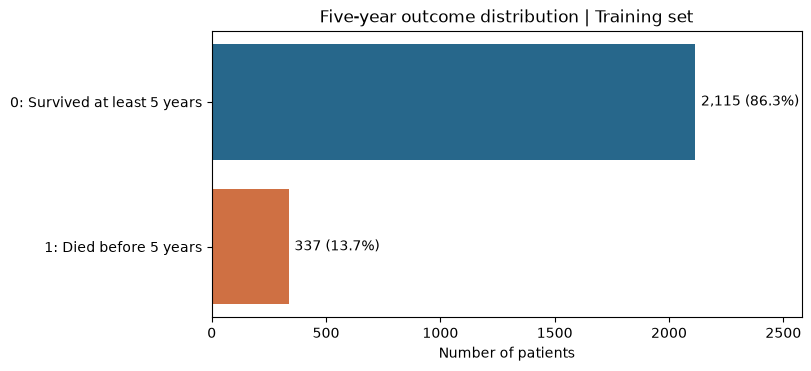

In [ ]:
outcome_counts = eda_train["label"].value_counts().reindex([0, 1], fill_value=0)
outcome_table = pd.DataFrame({
    "Patients": outcome_counts,
    "Training set (%)": (100 * outcome_counts / len(eda_train)).round(1),
})
outcome_table.index = ["0: Survived at least 5 years", "1: Died before 5 years"]
display(outcome_table)

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
bars = ax.barh(outcome_table.index, outcome_counts.to_numpy(), color=["#27678b", "#cf7043"])
ax.invert_yaxis()
ax.set_title("Five-year outcome distribution | Training set")
ax.set_xlabel("Number of patients")
ax.set_xlim(0, max(outcome_counts) * 1.22)
for bar, count in zip(bars, outcome_counts):
    ax.text(count + len(eda_train) * 0.01, bar.get_y() + bar.get_height() / 2,
            f"{count:,} ({count / len(eda_train):.1%})", va="center")
plt.show()


## 6. Numerical Variables

The four original numerical features describe age, tumor size and regional lymph node counts. Summary statistics show center, spread and observed range. Extreme observations may be clinically plausible; they should not be removed automatically.

### 6.1 Numerical Summary and Outcome Comparison

The first table summarizes the whole training set. The second compares the median of each feature between the two outcome groups; medians alone do not show the full distribution or establish a causal relationship.


In [ ]:
numeric_summary = eda_train[EDA_NUM_COLS].describe().T.rename(columns={
    "count": "Patients", "mean": "Mean", "std": "Std. deviation",
    "min": "Minimum", "25%": "25th percentile", "50%": "Median",
    "75%": "75th percentile", "max": "Maximum",
})
display(numeric_summary.round(2))

median_by_outcome = eda_train.groupby("label")[EDA_NUM_COLS].median().T
median_by_outcome.columns = ["Class 0: survived ≥5 years", "Class 1: died <5 years"]
print("Median by outcome group")
display(median_by_outcome.round(2))


,Patients,Mean,Std. deviation,Minimum,25th percentile,Median,75th percentile,Maximum
Age,2452.0,54.15,8.99,30.0,47.0,55.0,62.0,69.0
Tumor Size,2452.0,30.76,21.31,1.0,16.0,25.0,38.0,140.0
Regional Node Examined,2452.0,14.42,8.09,1.0,9.0,14.0,19.0,60.0
Reginol Node Positive,2452.0,4.27,5.21,1.0,1.0,2.0,5.0,46.0


Median by outcome group


,Class 0: survived ≥5 years,Class 1: died <5 years
Age,54.0,57.0
Tumor Size,23.0,33.0
Regional Node Examined,14.0,14.0
Reginol Node Positive,2.0,5.0


### 6.2 Histograms: Distribution of Each Numerical Feature

Each histogram shows the number of training patients in each range. The panels use the original units, making it easier to see skewness, common values and long tails.


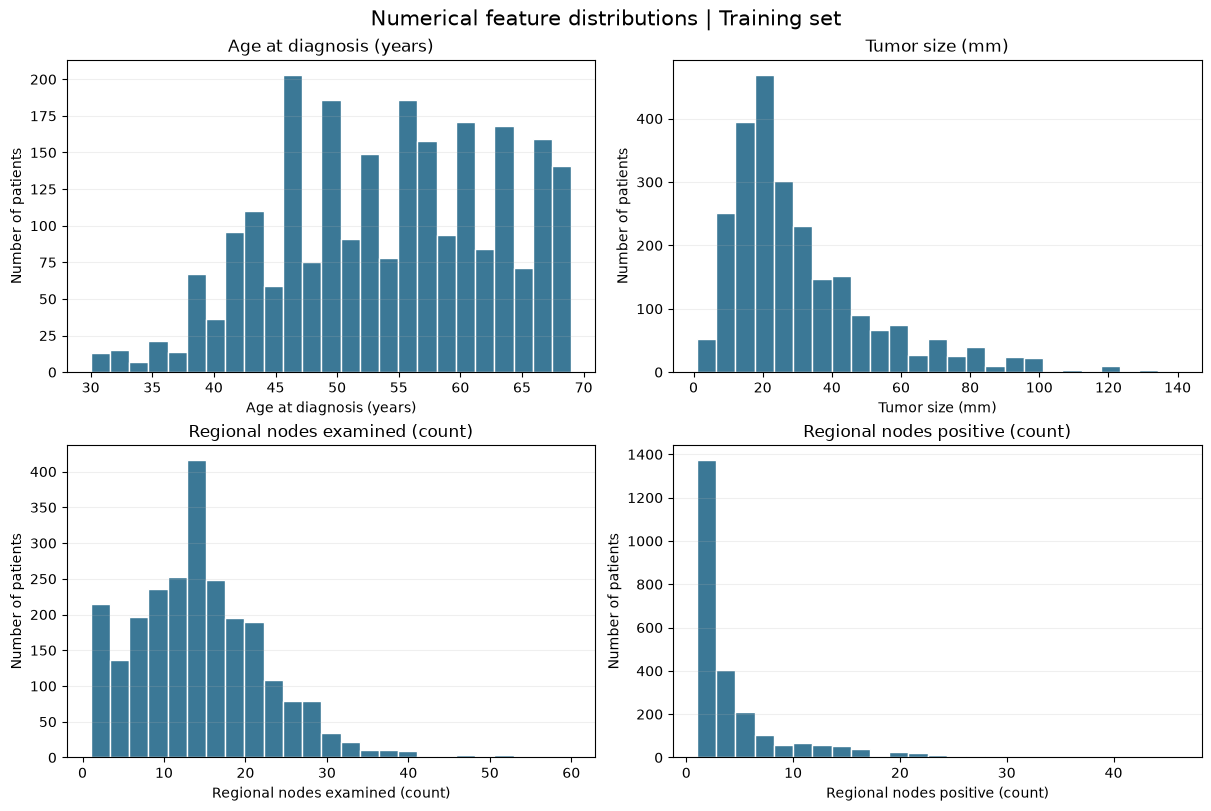

In [ ]:
NUM_LABELS = {
    "Age": "Age at diagnosis (years)",
    "Tumor Size": "Tumor size (mm)",
    "Regional Node Examined": "Regional nodes examined (count)",
    "Reginol Node Positive": "Regional nodes positive (count)",
}
n_rows = (len(EDA_NUM_COLS) + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 4 * n_rows), layout="constrained")
for ax, col in zip(axes.flat, EDA_NUM_COLS):
    ax.hist(eda_train[col].dropna(), bins=25, color="#3b7896", edgecolor="white")
    ax.set_title(NUM_LABELS[col])
    ax.set_xlabel(NUM_LABELS[col])
    ax.set_ylabel("Number of patients")
    ax.grid(axis="y", alpha=0.2)
for ax in list(axes.flat)[len(EDA_NUM_COLS):]:
    ax.remove()  # Hide an unused panel when the number of features is odd.
fig.suptitle("Numerical feature distributions | Training set", fontsize=15)
plt.show()


### 6.3 Box Plots: Numerical Features by Outcome

The center line is the median and the box spans the middle 50% of each group. Whiskers and individual points show the spread using the standard box-plot rule; points beyond the whiskers are not necessarily data errors. Compare both the overlap and the sample sizes, as the outcome groups are unequal.


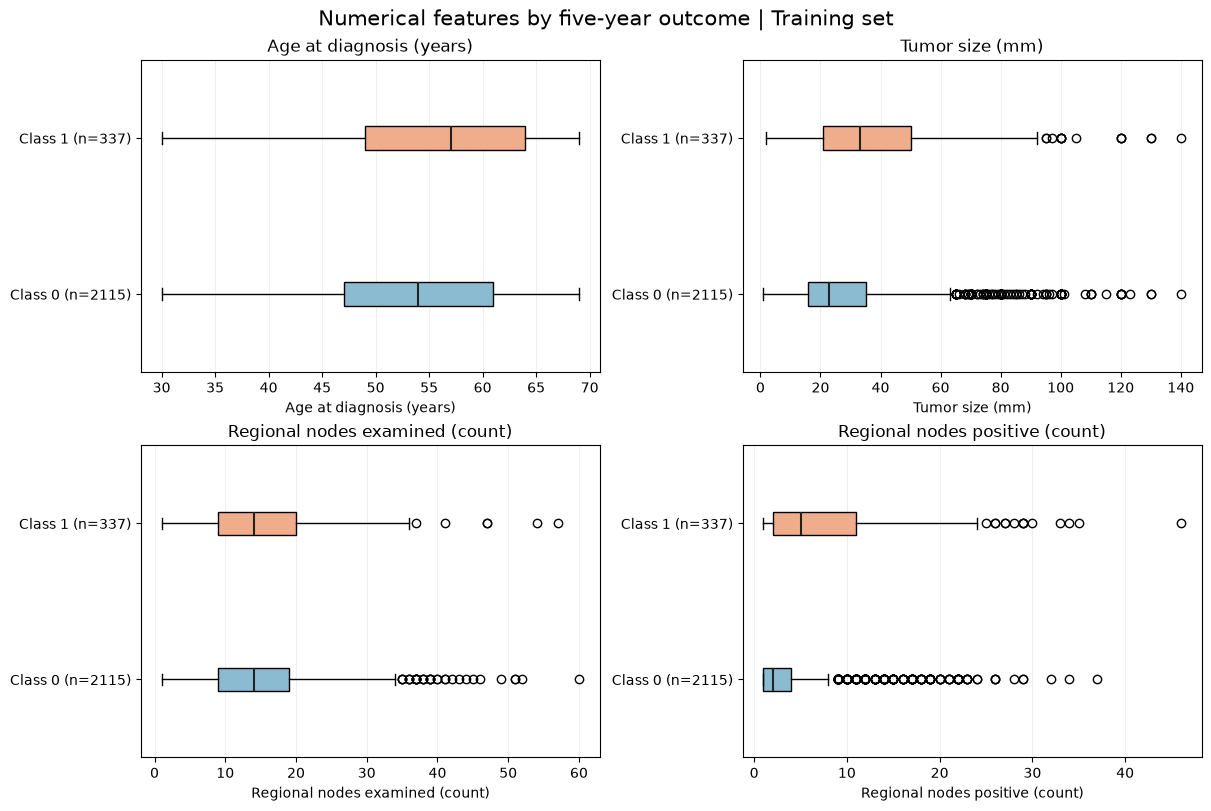

In [ ]:
from inspect import signature

n_rows = (len(EDA_NUM_COLS) + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 4 * n_rows), layout="constrained")
for ax, col in zip(axes.flat, EDA_NUM_COLS):
    groups = [eda_train.loc[eda_train["label"] == label, col].dropna() for label in (0, 1)]
    # Matplotlib renamed the horizontal-orientation option in version 3.10.
    orientation = {"orientation": "horizontal"} if "orientation" in signature(ax.boxplot).parameters else {"vert": False}
    boxes = ax.boxplot(groups, patch_artist=True, **orientation,
                       medianprops={"color": "#222222", "linewidth": 1.5})
    for patch, color in zip(boxes["boxes"], ["#8bbbd0", "#efad8b"]):
        patch.set_facecolor(color)
    ax.set_yticks([1, 2], [f"Class 0 (n={len(groups[0])})", f"Class 1 (n={len(groups[1])})"])
    ax.set_title(NUM_LABELS[col])
    ax.set_xlabel(NUM_LABELS[col])
    ax.grid(axis="x", alpha=0.2)
for ax in list(axes.flat)[len(EDA_NUM_COLS):]:
    ax.remove()  # Hide an unused panel when the number of features is odd.
fig.suptitle("Numerical features by five-year outcome | Training set", fontsize=15)
plt.show()


### 6.4 Basic Data-Quality Checks

Check missing values and whether the number of positive nodes exceeds the number examined. A passing check does not prove every observation is correct; it only addresses these specific conditions.


In [ ]:
missing_by_feature = eda_train[X_train.columns].isna().sum().rename("Missing values")
display(missing_by_feature.to_frame())
node_inconsistencies = (eda_train["Reginol Node Positive"] > eda_train["Regional Node Examined"]).sum()
print(f"Patients with more positive nodes than examined: {node_inconsistencies}")


,Missing values
Age,0
Race,0
Marital Status,0
T Stage,0
N Stage,0
6th Stage,0
Grade,0
A Stage,0
Tumor Size,0
Estrogen Status,0


Patients with more positive nodes than examined: 0


## 7. Categorical Variables

For each variable, the table and chart show the number of training patients and the percentage who died before five years **within that category**. The dashed line marks the overall event percentage in the training set. Percentages from small groups, such as Grade IV, should be interpreted cautiously.

These comparisons are descriptive. They do not adjust for other clinical or social variables and do not identify the cause of group differences.


In [ ]:
# Keep clinically ordered categories in their meaningful order in tables and plots.
CATEGORY_ORDER = {
    "T Stage": ["T1", "T2", "T3", "T4"],
    "N Stage": ["N1", "N2", "N3"],
    "6th Stage": ["IIA", "IIB", "IIIA", "IIIB", "IIIC"],
    "Grade": ["Well differentiated; Grade I", "Moderately differentiated; Grade II",
              "Poorly differentiated; Grade III", "Undifferentiated; anaplastic; Grade IV"],
}

def show_categorical_eda(column):
    # Calculate counts and the event proportion within each category.
    table = eda_train.groupby(column, dropna=False)["label"].agg(
        Patients="size", Events="sum", event_rate="mean"
    )
    if column in CATEGORY_ORDER:
        ordered = [value for value in CATEGORY_ORDER[column] if value in table.index]
        ordered += [value for value in table.index if value not in ordered]
        table = table.loc[ordered]
    else:
        table = table.sort_values("Patients", ascending=False)
    table["Training set (%)"] = 100 * table["Patients"] / len(eda_train)
    table["Deaths before 5 years (%)"] = 100 * table["event_rate"]
    shown = table[["Patients", "Training set (%)", "Events", "Deaths before 5 years (%)"]]
    display(shown.round(1))

    labels = ["\n".join(textwrap.wrap(str(value), width=30)) for value in table.index]
    positions = np.arange(len(table))
    fig, (ax_count, ax_rate) = plt.subplots(
        1, 2, figsize=(12, max(3.5, len(table) * 0.65 + 2)),
        gridspec_kw={"width_ratios": [1.1, 1]}, layout="constrained"
    )
    ax_count.barh(positions, table["Patients"], color="#3b7896")
    ax_count.set_yticks(positions, labels)
    ax_count.invert_yaxis()
    ax_count.set_xlabel("Number of patients")
    ax_count.set_title("Category size")
    ax_count.set_xlim(0, table["Patients"].max() * 1.22)
    for y, count in zip(positions, table["Patients"]):
        ax_count.text(count + table["Patients"].max() * 0.02, y, f"{count:,}", va="center")

    rates = table["Deaths before 5 years (%)"]
    ax_rate.barh(positions, rates, color="#d27d55")
    ax_rate.set_yticks(positions, [""] * len(positions))
    ax_rate.invert_yaxis()
    overall_rate = 100 * eda_train["label"].mean()
    ax_rate.axvline(overall_rate, color="#333333", linestyle="--", linewidth=1,
                    label=f"Overall: {overall_rate:.1f}%")
    ax_rate.set_xlabel("Deaths before 5 years (%)")
    ax_rate.set_title("Outcome within each category")
    ax_rate.set_xlim(0, max(rates.max(), overall_rate) * 1.30 + 1)
    for y, rate in zip(positions, rates):
        ax_rate.text(rate + 0.7, y, f"{rate:.1f}%", va="center")
    ax_rate.legend(loc="lower right", fontsize=9)
    fig.suptitle(f"{column} | Training set", fontsize=14)
    plt.show()


### 7.1 Race

Compare representation and outcome proportions across the dataset categories. Unequal group sizes and the broad Other category matter for later fairness analysis.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Race,,,,
White,2083,85.0,280,13.4
Black,186,7.6,42,22.6
"Other (American Indian/AK Native, Asian/Pacific Islander)",183,7.5,15,8.2


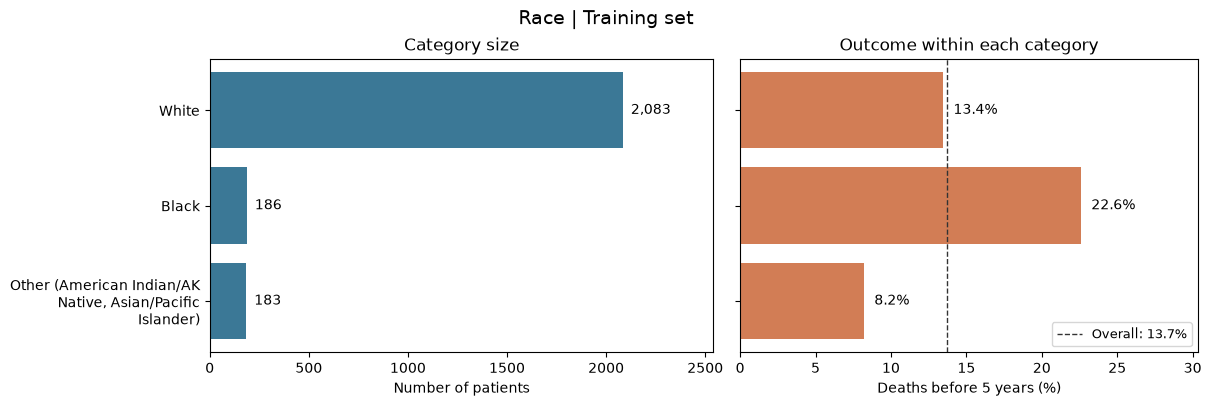

In [ ]:
show_categorical_eda("Race")


### 7.2 Marital Status

Examine the distribution and note groups with few patients. Any association can reflect multiple social and clinical factors.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Marital Status,,,,
Married (including common law),1582,64.5,182,11.5
Single (never married),374,15.3,61,16.3
Divorced,318,13.0,57,17.9
Widowed,148,6.0,28,18.9
Separated,30,1.2,9,30.0


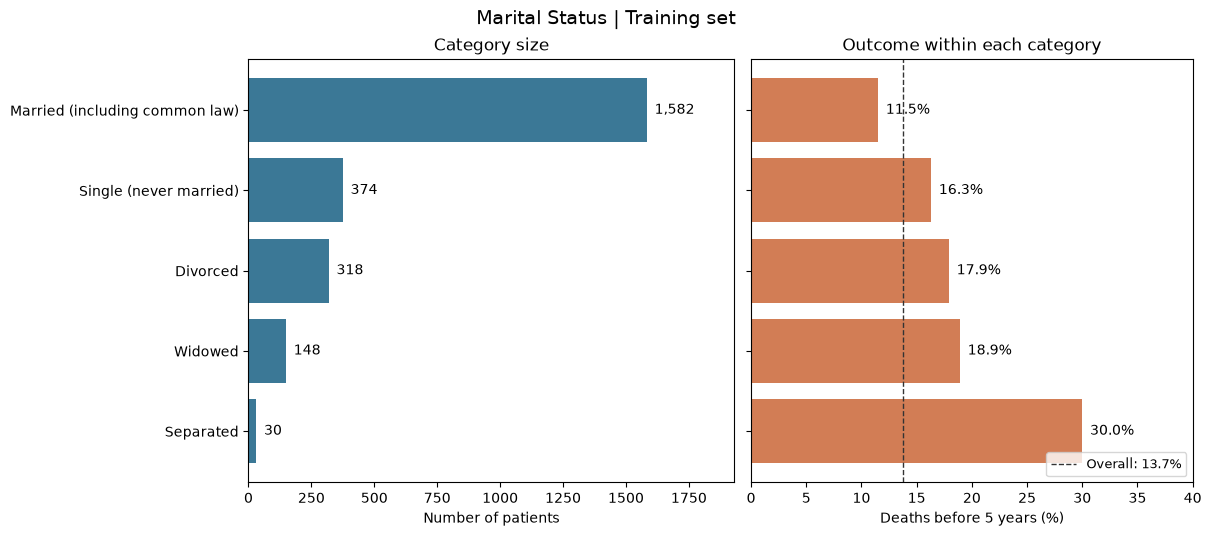

In [ ]:
show_categorical_eda("Marital Status")


### 7.3 T Stage

Compare the ordered primary tumor stages. The percentages describe this training sample, rather than the effect of stage alone.


,Patients,Training set (%),Events,Deaths before 5 years (%)
T Stage,,,,
T1,971,39.6,78,8.0
T2,1068,43.6,164,15.4
T3,340,13.9,69,20.3
T4,73,3.0,26,35.6


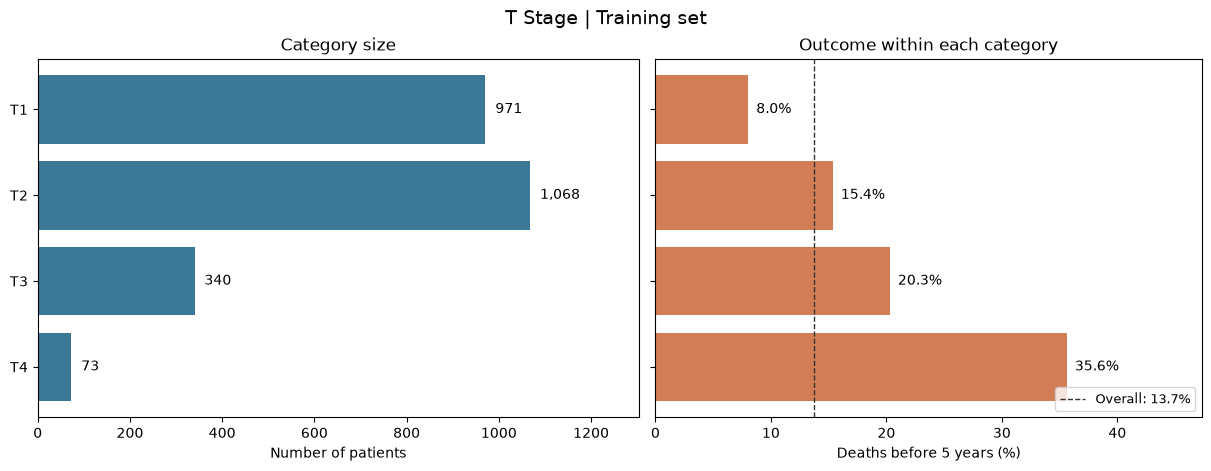

In [ ]:
show_categorical_eda("T Stage")


### 7.4 N Stage

Compare the ordered regional lymph node stages and the size of each group.


,Patients,Training set (%),Events,Deaths before 5 years (%)
N Stage,,,,
N1,1639,66.8,139,8.5
N2,500,20.4,90,18.0
N3,313,12.8,108,34.5


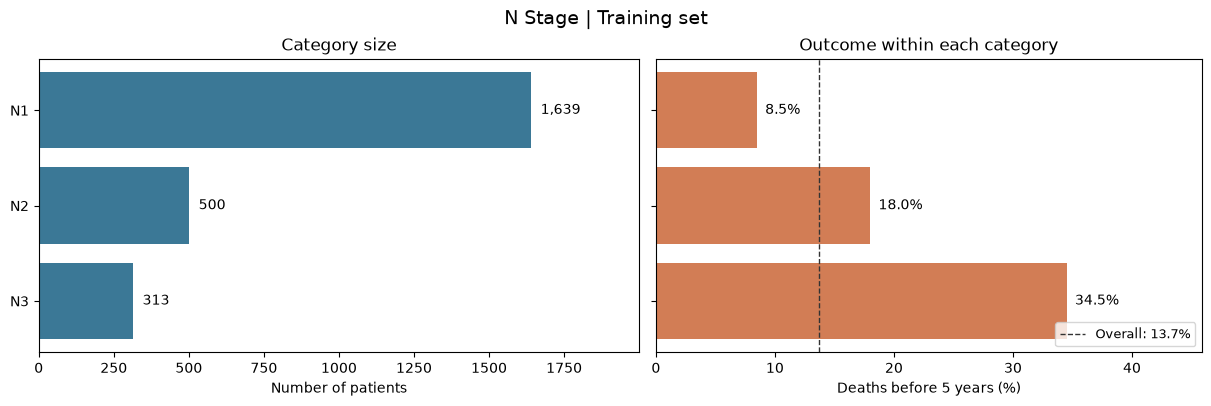

In [ ]:
show_categorical_eda("N Stage")


### 7.5 6th Stage

Inspect the overall stage and consider its overlap with T and N stages. Some categories may have few patients.


,Patients,Training set (%),Events,Deaths before 5 years (%)
6th Stage,,,,
IIA,793,32.3,51,6.4
IIB,661,27.0,63,9.5
IIIA,639,26.1,102,16.0
IIIB,46,1.9,13,28.3
IIIC,313,12.8,108,34.5


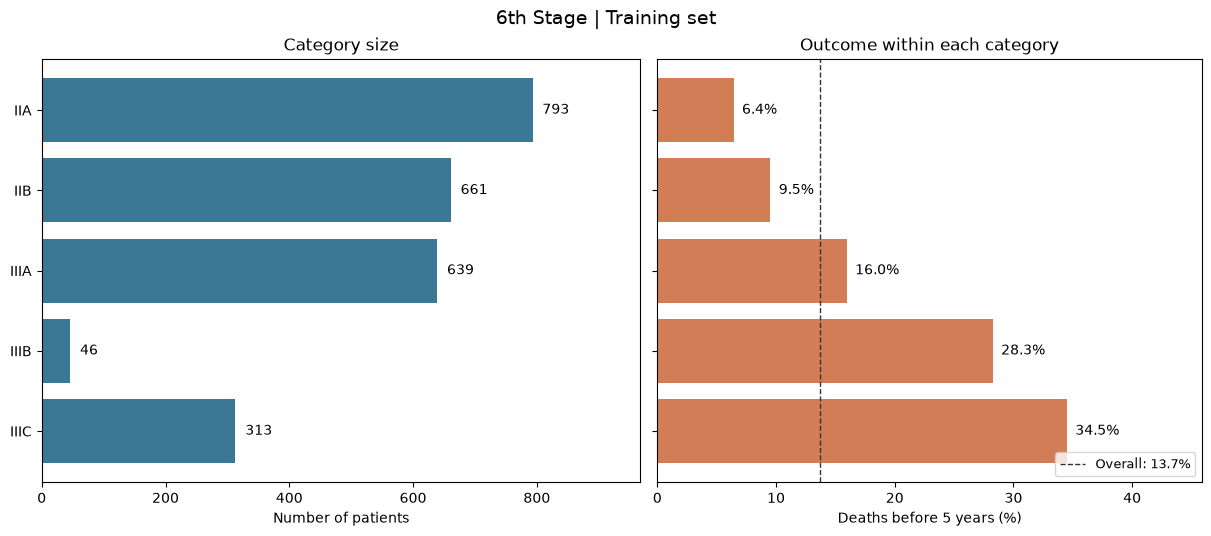

In [ ]:
show_categorical_eda("6th Stage")


### 7.6 Grade

Compare ordered histological grades. Pay particular attention to the small Grade IV group.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Grade,,,,
Well differentiated; Grade I,303,12.4,19,6.3
Moderately differentiated; Grade II,1438,58.6,165,11.5
Poorly differentiated; Grade III,699,28.5,147,21.0
Undifferentiated; anaplastic; Grade IV,12,0.5,6,50.0


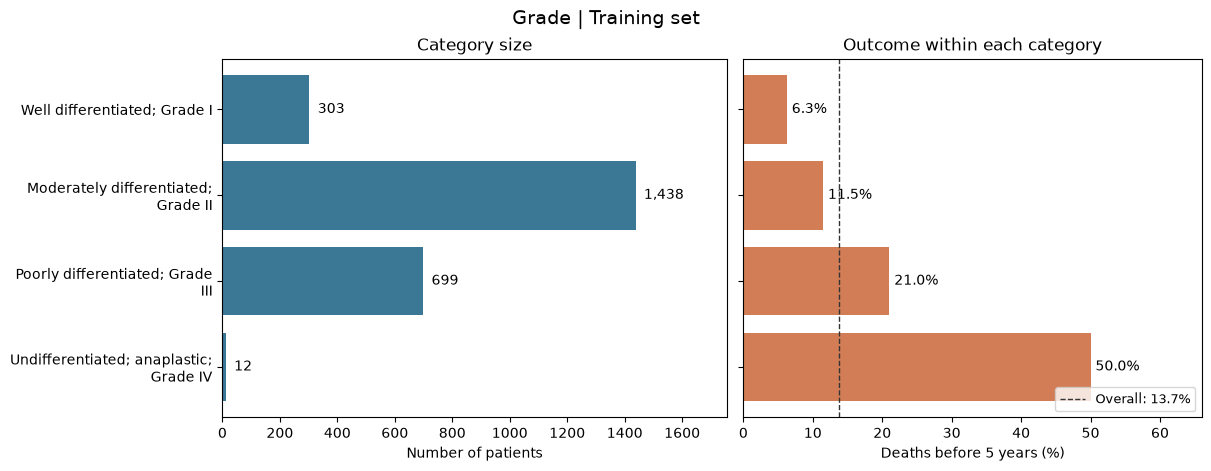

In [ ]:
show_categorical_eda("Grade")


### 7.7 A Stage

Compare Regional and Distant categories, and check group sizes before interpreting their percentages.


,Patients,Training set (%),Events,Deaths before 5 years (%)
A Stage,,,,
Regional,2397,97.8,317,13.2
Distant,55,2.2,20,36.4


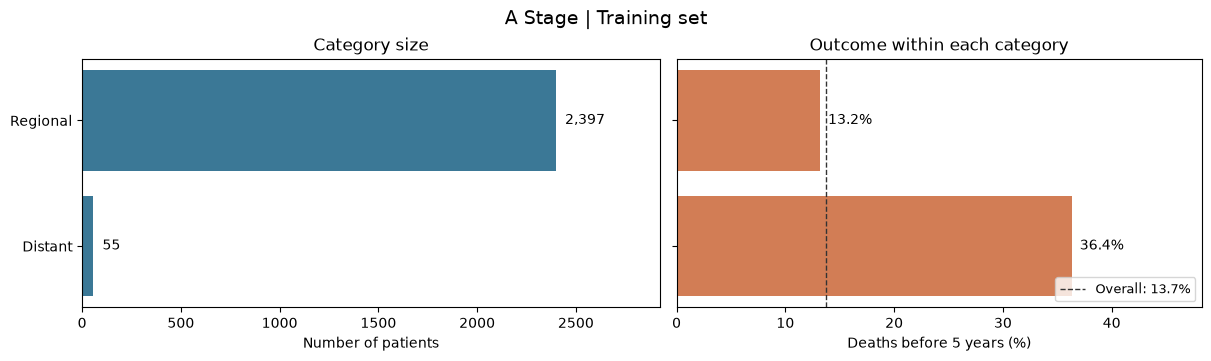

In [ ]:
show_categorical_eda("A Stage")


### 7.8 Estrogen Status

Compare receptor categories. The observed difference is not an adjusted effect of receptor status.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Estrogen Status,,,,
Positive,2267,92.5,268,11.8
Negative,185,7.5,69,37.3


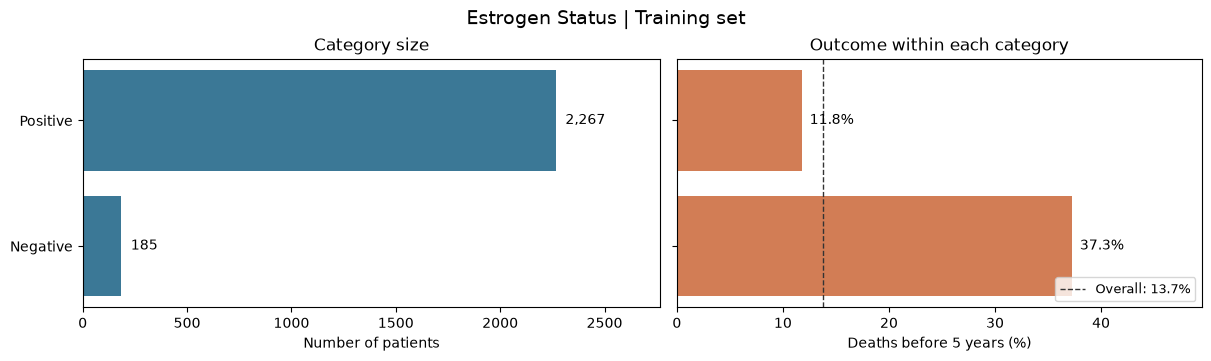

In [ ]:
show_categorical_eda("Estrogen Status")


### 7.9 Progesterone Status

Compare receptor categories and their within-group outcome proportions.


,Patients,Training set (%),Events,Deaths before 5 years (%)
Progesterone Status,,,,
Positive,2007,81.9,209,10.4
Negative,445,18.1,128,28.8


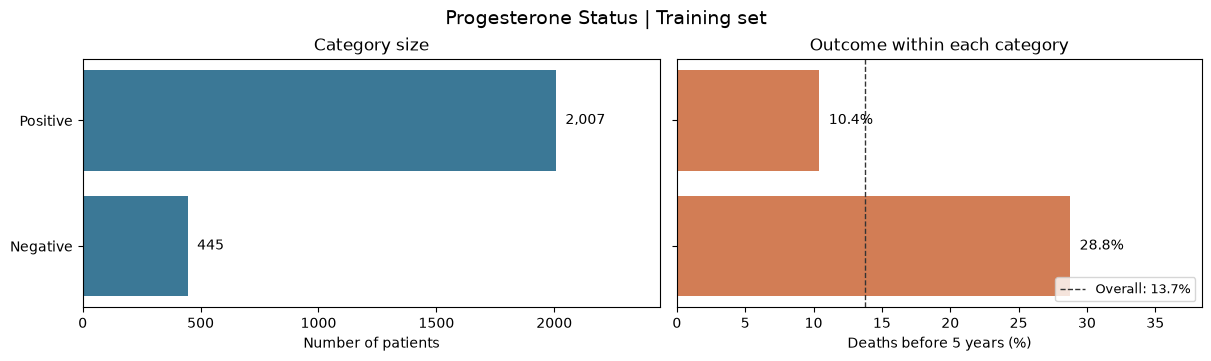

In [ ]:
show_categorical_eda("Progesterone Status")


## 8. EDA Interpretation and Next Decisions

- The class distribution should guide metric selection; accuracy alone can hide poor performance on class 1.
- Review numerical distributions before choosing transformations. Do not remove extreme values without checking their meaning.
- Small categorical groups can have unstable outcome proportions and deserve attention in model evaluation and fairness analysis.
- T Stage, N Stage and Grade have a clinical order; consider how to encode them and the assumptions this imposes for each model.
- 6th Stage is related to other staging variables. Assess feature redundancy during model development.
- Early-censored patients were excluded, and the data may not represent all patient populations. Consider these limits when interpreting results.


## 9. Relationships Between Features

This section compares **every pair of the 13 original input features** in the training set. We use raw training features, not the target or test set. Different methods are needed because numerical and categorical variables represent information differently:

- **Numerical–numerical:** Spearman rank correlation (−1 to +1), including direction.
- **Categorical–categorical:** Cramér’s V (0 to 1), a symmetric measure of association without direction.
- **Numerical–categorical:** correlation ratio η (0 to 1), describing how much of a numerical variable’s variation lies between categories, without direction.

The methods measure different relationships, so their values should not be compared as if they were the same metric. These are descriptive associations, not causation or an automatic rule for dropping features. Rare categories can make estimates unstable; uncorrected Cramér’s V can be inflated in sparse tables. T Stage, N Stage and Grade are treated as categories here, so Cramér’s V does not use their ordering.


In [ ]:
from itertools import combinations
from scipy.stats import chi2_contingency

# Use the original training features rather than encoded values or test data.
relationship_data = X_train.copy()
NUM_FEATURES = list(NUM_COLS)
CAT_FEATURES = list(ORD_COLS) + list(CAT_COLS)
assert set(NUM_FEATURES + CAT_FEATURES) == set(relationship_data.columns)

def cramers_v(first, second):
    # Calculate uncorrected Cramér's V using observations available for both features.
    pairs = pd.concat([first, second], axis=1).dropna()
    table = pd.crosstab(pairs.iloc[:, 0], pairs.iloc[:, 1])
    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return float(np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1))))

def correlation_ratio(numerical, categorical):
    # Compare variation between category means with total numerical variation.
    pairs = pd.DataFrame({"value": numerical, "group": categorical}).dropna()
    if len(pairs) < 2 or pairs["group"].nunique() < 2:
        return np.nan
    total = ((pairs["value"] - pairs["value"].mean()) ** 2).sum()
    if total == 0:
        return np.nan
    groups = pairs.groupby("group")["value"].agg(["size", "mean"])
    between = (groups["size"] * (groups["mean"] - pairs["value"].mean()) ** 2).sum()
    return float(np.sqrt(np.clip(between / total, 0, 1)))

def plot_relationship_matrix(matrix, title, label, *, cmap, vmin, vmax):
    fig, ax = plt.subplots(figsize=(max(8, matrix.shape[1] * 1.3),
                                   max(4.5, matrix.shape[0] * 0.8)), layout="constrained")
    image = ax.imshow(matrix.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(matrix.shape[1]), matrix.columns, rotation=40, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(matrix.shape[0]), matrix.index)
    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            value = matrix.iat[row, col]
            if pd.notna(value):
                red, green, blue, _ = image.cmap(image.norm(value))
                luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
                color = "white" if luminance < 0.50 else "black"
                ax.text(col, row, f"{value:.2f}", ha="center", va="center", color=color, fontsize=9)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label=label, shrink=0.85)
    plt.show()


### 9.1 Numerical–Numerical Pairs: Spearman Correlation

Spearman correlation compares ranks. Positive values indicate that higher values tend to occur together; negative values indicate opposite rank trends. Values near zero do not rule out non-monotonic relationships. The diagonal compares each feature with itself.


,Age,Tumor Size,Regional Node Examined,Reginol Node Positive
Age,1.000,-0.111,-0.032,-0.001
Tumor Size,-0.111,1.000,0.133,0.339
Regional Node Examined,-0.032,0.133,1.000,0.378
Reginol Node Positive,-0.001,0.339,0.378,1.000


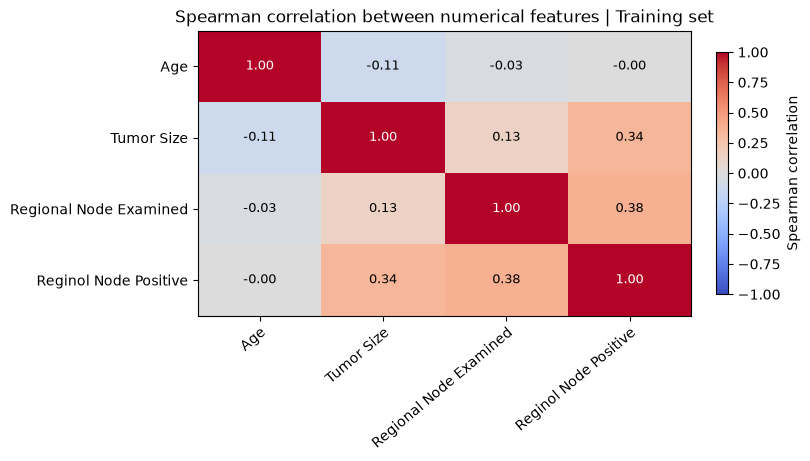

In [ ]:
spearman_matrix = relationship_data[NUM_FEATURES].corr(method="spearman")
display(spearman_matrix.round(3))
plot_relationship_matrix(spearman_matrix, "Spearman correlation between numerical features | Training set",
                         "Spearman correlation", cmap="coolwarm", vmin=-1, vmax=1)


### 9.2 Categorical–Categorical Pairs: Cramér’s V

Each off-diagonal cell summarizes one pair of categorical variables. Zero indicates little detected association and larger values indicate stronger association; the value has no positive or negative direction. Examine category counts before interpreting high scores, especially for rare Grade IV or small social groups. The diagonal is one for nonconstant features.


,T Stage,N Stage,Grade,Race,Marital Status,6th Stage,A Stage,Estrogen Status,Progesterone Status
T Stage,1.000,0.213,0.076,0.030,0.042,0.747,0.446,0.087,0.053
N Stage,0.213,1.000,0.127,0.032,0.058,0.909,0.253,0.100,0.092
Grade,0.076,0.127,1.000,0.045,0.055,0.116,0.041,0.232,0.174
Race,0.030,0.032,0.045,1.000,0.140,0.035,0.012,0.057,0.033
Marital Status,0.042,0.058,0.055,0.140,1.000,0.048,0.057,0.065,0.067
6th Stage,0.747,0.909,0.116,0.035,0.048,1.000,0.435,0.126,0.099
A Stage,0.446,0.253,0.041,0.012,0.057,0.435,1.000,0.051,0.014
Estrogen Status,0.087,0.100,0.232,0.057,0.065,0.126,0.051,1.000,0.527
Progesterone Status,0.053,0.092,0.174,0.033,0.067,0.099,0.014,0.527,1.000


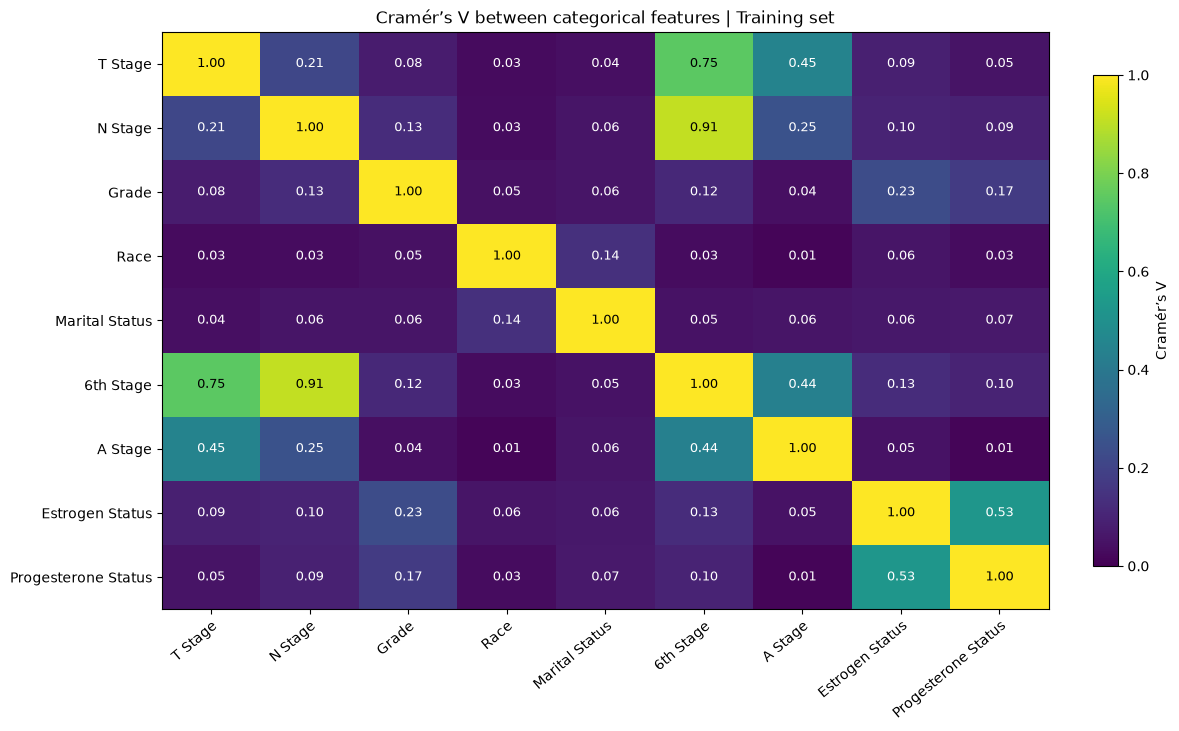

In [ ]:
cramers_matrix = pd.DataFrame(np.nan, index=CAT_FEATURES, columns=CAT_FEATURES, dtype=float)
for feature in CAT_FEATURES:
    if relationship_data[feature].nunique(dropna=True) > 1:
        cramers_matrix.loc[feature, feature] = 1.0
for first, second in combinations(CAT_FEATURES, 2):
    value = cramers_v(relationship_data[first], relationship_data[second])
    cramers_matrix.loc[first, second] = value
    cramers_matrix.loc[second, first] = value

display(cramers_matrix.round(3))
plot_relationship_matrix(cramers_matrix, "Cramér’s V between categorical features | Training set",
                         "Cramér’s V", cmap="viridis", vmin=0, vmax=1)


### 9.3 Clinical Stages: Detailed Cross-Tabulations

These are the stage comparisons previously placed before the EDA, now grouped with feature relationships. For each row category, the first table shows patient counts and the second shows percentages across 6th Stage categories. Each percentage uses its own row total as denominator. Small row counts make percentages less stable.


In [ ]:
for column in ["T Stage", "N Stage", "A Stage"]:
    counts = pd.crosstab(X_train[column], X_train["6th Stage"])
    row_percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    print(f"\n{column} vs 6th Stage: number of patients")
    display(counts)
    print(f"{column} vs 6th Stage: percentages within each {column} category")
    display(row_percentages.round(1))



T Stage vs 6th Stage: number of patients


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
T Stage,,,,,
T1,793,0,121,0,57
T2,0,661,253,0,154
T3,0,0,265,0,75
T4,0,0,0,46,27


T Stage vs 6th Stage: percentages within each T Stage category


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
T Stage,,,,,
T1,81.7,0.0,12.5,0.0,5.9
T2,0.0,61.9,23.7,0.0,14.4
T3,0.0,0.0,77.9,0.0,22.1
T4,0.0,0.0,0.0,63.0,37.0



N Stage vs 6th Stage: number of patients


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
N Stage,,,,,
N1,793,661,165,20,0
N2,0,0,474,26,0
N3,0,0,0,0,313


... (2 outputs left out)


A Stage vs 6th Stage: number of patients


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
A Stage,,,,,
Distant,0,0,0,18,37
Regional,793,661,639,28,276


A Stage vs 6th Stage: percentages within each A Stage category


6th Stage,IIA,IIB,IIIA,IIIB,IIIC
A Stage,,,,,
Distant,0.0,0.0,0.0,32.7,67.3
Regional,33.1,27.6,26.7,1.2,11.5


### 9.4 Numerical–Categorical Pairs: Correlation Ratio η

For each numerical and categorical pair, η summarizes the variation in the numerical feature explained by differences between category means. A larger value indicates greater separation of group means relative to overall variation. η has no direction, does not establish causality and can be sensitive to small groups and extreme values.


,T Stage,N Stage,Grade,Race,Marital Status,6th Stage,A Stage,Estrogen Status,Progesterone Status
Age,0.113,0.047,0.129,0.081,0.262,0.088,0.008,0.064,0.009
Tumor Size,0.872,0.277,0.132,0.022,0.037,0.605,0.141,0.089,0.075
Regional Node Examined,0.127,0.337,0.087,0.014,0.029,0.341,0.045,0.042,0.019
Reginol Node Positive,0.256,0.871,0.149,0.032,0.077,0.857,0.193,0.094,0.081


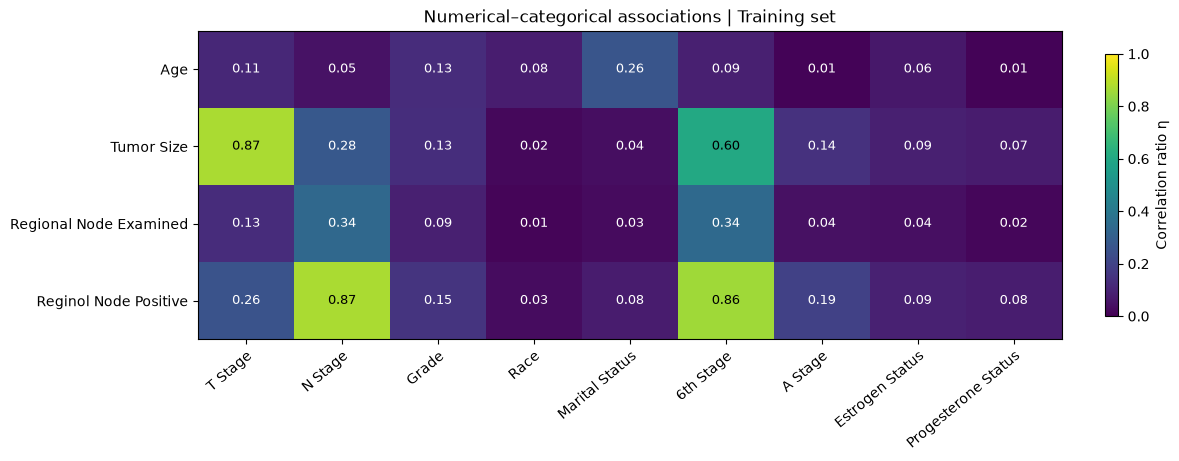

In [ ]:
eta_matrix = pd.DataFrame(index=NUM_FEATURES, columns=CAT_FEATURES, dtype=float)
for numerical in NUM_FEATURES:
    for categorical in CAT_FEATURES:
        eta_matrix.loc[numerical, categorical] = correlation_ratio(
            relationship_data[numerical], relationship_data[categorical]
        )
display(eta_matrix.round(3))
plot_relationship_matrix(eta_matrix, "Numerical–categorical associations | Training set",
                         "Correlation ratio η", cmap="viridis", vmin=0, vmax=1)


### 9.5 Example: Tumor Size by T Stage

This box plot complements the summary score with the actual distributions. The labels show group sizes; the central line and box represent the median and middle 50%. Points beyond the whiskers are not automatically erroneous observations.


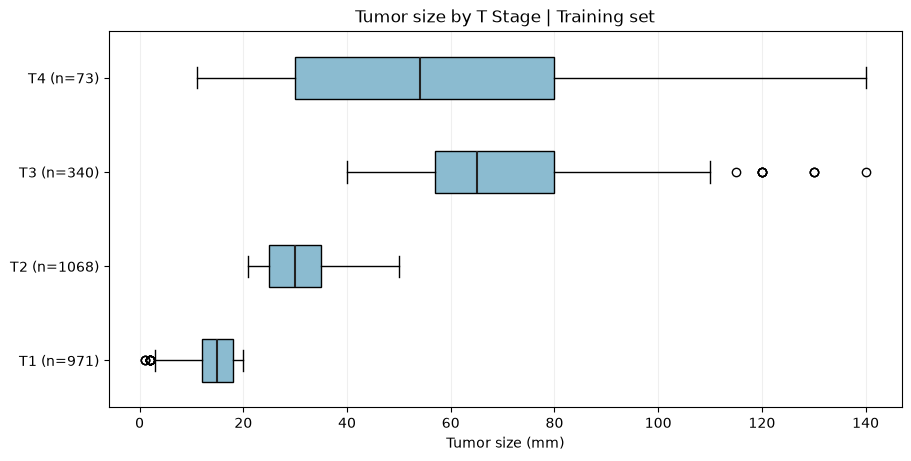

In [ ]:
from inspect import signature
stage_order = [stage for stage in ["T1", "T2", "T3", "T4"]
               if stage in relationship_data["T Stage"].dropna().unique()]
stage_groups = [relationship_data.loc[relationship_data["T Stage"] == stage, "Tumor Size"].dropna()
                for stage in stage_order]
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
orientation = {"orientation": "horizontal"} if "orientation" in signature(ax.boxplot).parameters else {"vert": False}
boxes = ax.boxplot(stage_groups, patch_artist=True, **orientation,
                   medianprops={"color": "#222222", "linewidth": 1.5})
for patch in boxes["boxes"]:
    patch.set_facecolor("#8bbbd0")
ax.set_yticks(range(1, len(stage_order) + 1),
              [f"{stage} (n={len(group)})" for stage, group in zip(stage_order, stage_groups)])
ax.set_xlabel("Tumor size (mm)")
ax.set_title("Tumor size by T Stage | Training set")
ax.grid(axis="x", alpha=0.2)
plt.show()


### 9.6 Complete Pairwise Results

The tables below list **all unique pairs** with the number of complete observations used. Numerical pairs retain the sign of Spearman correlation; the other two metrics are unsigned. Sorting highlights larger values within each method, but does not determine which variables should be kept or removed.


In [ ]:
pair_results = []
for first, second in combinations(NUM_FEATURES, 2):
    pair_results.append({"Type": "Numerical–numerical", "Feature 1": first, "Feature 2": second,
                         "Metric": "Spearman", "Value": spearman_matrix.loc[first, second],
                         "Patients": relationship_data[[first, second]].dropna().shape[0]})
for first, second in combinations(CAT_FEATURES, 2):
    pair_results.append({"Type": "Categorical–categorical", "Feature 1": first, "Feature 2": second,
                         "Metric": "Cramér’s V", "Value": cramers_matrix.loc[first, second],
                         "Patients": relationship_data[[first, second]].dropna().shape[0]})
for numerical in NUM_FEATURES:
    for categorical in CAT_FEATURES:
        pair_results.append({"Type": "Numerical–categorical", "Feature 1": numerical, "Feature 2": categorical,
                             "Metric": "Correlation ratio η", "Value": eta_matrix.loc[numerical, categorical],
                             "Patients": relationship_data[[numerical, categorical]].dropna().shape[0]})

pairwise_results = pd.DataFrame(pair_results)
assert len(pairwise_results) == len(list(combinations(relationship_data.columns, 2)))
for kind in ["Numerical–numerical", "Categorical–categorical", "Numerical–categorical"]:
    rows = pairwise_results[pairwise_results["Type"] == kind].copy()
    rows = rows.sort_values("Value", key=lambda values: values.abs(), ascending=False)
    print(f"{kind}: {len(rows)} unique pairs")
    display(rows.drop(columns="Type").reset_index(drop=True).round({"Value": 3}))


Numerical–numerical: 6 unique pairs


,Feature 1,Feature 2,Metric,Value,Patients
0,Regional Node Examined,Reginol Node Positive,Spearman,0.378,2452
1,Tumor Size,Reginol Node Positive,Spearman,0.339,2452
2,Tumor Size,Regional Node Examined,Spearman,0.133,2452
3,Age,Tumor Size,Spearman,-0.111,2452
4,Age,Regional Node Examined,Spearman,-0.032,2452
5,Age,Reginol Node Positive,Spearman,-0.001,2452


Categorical–categorical: 36 unique pairs


,Feature 1,Feature 2,Metric,Value,Patients
0,N Stage,6th Stage,Cramér’s V,0.909,2452
1,T Stage,6th Stage,Cramér’s V,0.747,2452
2,Estrogen Status,Progesterone Status,Cramér’s V,0.527,2452
3,T Stage,A Stage,Cramér’s V,0.446,2452
4,6th Stage,A Stage,Cramér’s V,0.435,2452
5,N Stage,A Stage,Cramér’s V,0.253,2452
6,Grade,Estrogen Status,Cramér’s V,0.232,2452
7,T Stage,N Stage,Cramér’s V,0.213,2452
8,Grade,Progesterone Status,Cramér’s V,0.174,2452
9,Race,Marital Status,Cramér’s V,0.140,2452


Numerical–categorical: 36 unique pairs


,Feature 1,Feature 2,Metric,Value,Patients
0,Tumor Size,T Stage,Correlation ratio η,0.872,2452
1,Reginol Node Positive,N Stage,Correlation ratio η,0.871,2452
2,Reginol Node Positive,6th Stage,Correlation ratio η,0.857,2452
3,Tumor Size,6th Stage,Correlation ratio η,0.605,2452
4,Regional Node Examined,6th Stage,Correlation ratio η,0.341,2452
5,Regional Node Examined,N Stage,Correlation ratio η,0.337,2452
6,Tumor Size,N Stage,Correlation ratio η,0.277,2452
7,Age,Marital Status,Correlation ratio η,0.262,2452
8,Reginol Node Positive,T Stage,Correlation ratio η,0.256,2452
9,Reginol Node Positive,A Stage,Correlation ratio η,0.193,2452


### 9.7 Interpretation

Use these results to formulate questions for feature engineering and model interpretation. High association can reflect shared clinical information, but does not by itself make a feature unnecessary. Low pairwise association does not rule out nonlinear or multivariable relationships. Revisit candidate feature choices during training-set model development, keeping the test set reserved for final evaluation.


## 10. Feature Engineering: Positive Node Ratio

The EDA suggested that the number of positive nodes and the number examined describe related but distinct information. We create the fraction of examined nodes that are positive:

**Positive Node Ratio = regional nodes positive / regional nodes examined**

For example, 4 positive nodes among 10 examined give a ratio of 0.4. Both original counts remain available in the raw data. For the initial model we retain the number examined and the ratio, while excluding the separate positive-node count; the ratio alone would not distinguish the same fraction calculated from different numbers of nodes. Creating the ratio is a hypothesis to evaluate later, not evidence that it improves prediction. Since the calculation is done independently for each patient and uses neither the outcome nor a learned population statistic, it can be applied safely to training rows.

The function checks for missing, zero or negative denominators and invalid positive counts. If any are present, it stops with an explanation rather than silently inventing a value. The held-out test set is not transformed in this section; apply the same function to it only when performing final evaluation.


In [ ]:
def add_positive_node_ratio(features):
    """Return a copy with the positive-node fraction, after checking both counts."""
    result = features.copy()
    examined = result["Regional Node Examined"]
    positive = result["Reginol Node Positive"]
    invalid = (examined.isna() | positive.isna() | (examined <= 0) |
               (positive < 0) | (positive > examined))
    if invalid.any():
        raise ValueError("Cannot calculate Positive Node Ratio: check examined and positive node counts.")
    result["Positive Node Ratio"] = positive / examined
    return result

# Keep the original training features available for EDA and create a separate modeling table.
X_train_fe = add_positive_node_ratio(X_train)
print("Original training shape:", X_train.shape)
print("Training shape with engineered feature:", X_train_fe.shape)
print("Positive Node Ratio summary:")
display(X_train_fe["Positive Node Ratio"].describe().round(3).to_frame())


Original training shape: (2452, 13)
Training shape with engineered feature: (2452, 14)
Positive Node Ratio summary:


,Positive Node Ratio
count,2452.000
mean,0.330
std,0.290
min,0.020
25%,0.103
50%,0.214
75%,0.500
max,1.000


### 10.1 Explore the New Feature

Compare the distribution and median in each outcome group using training data. Also examine the ratio’s Spearman correlations with its original component counts. These relationships are expected because the ratio is derived from the counts. Any observed difference is descriptive; model comparison is still needed to determine whether the ratio is useful.


,Patients,Median ratio
Class 0: survived ≥5 years,2115,0.200
Class 1: died <5 years,337,0.435


Spearman correlations with the original node counts:


,Regional Node Examined,Reginol Node Positive
Positive Node Ratio,-0.324,0.661


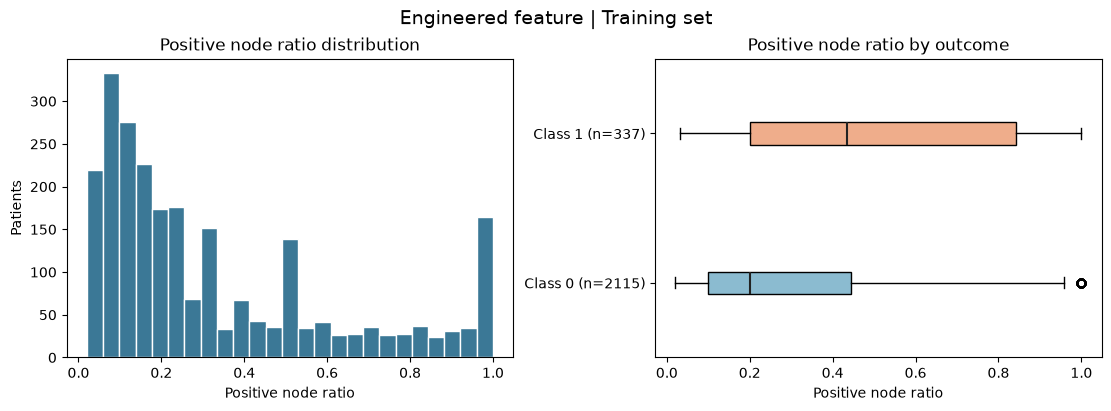

In [ ]:
ratio_eda = X_train_fe[["Positive Node Ratio"]].copy()
ratio_eda["label"] = y_train
ratio_by_outcome = ratio_eda.groupby("label")["Positive Node Ratio"].agg(["size", "median"])
ratio_by_outcome.index = ["Class 0: survived ≥5 years", "Class 1: died <5 years"]
display(ratio_by_outcome.rename(columns={"size": "Patients", "median": "Median ratio"}).round(3))

print("Spearman correlations with the original node counts:")
ratio_correlations = X_train_fe[["Positive Node Ratio", "Regional Node Examined", "Reginol Node Positive"]].corr(method="spearman")
display(ratio_correlations.loc[["Positive Node Ratio"], ["Regional Node Examined", "Reginol Node Positive"]].round(3))

from inspect import signature
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].hist(ratio_eda["Positive Node Ratio"], bins=25, color="#3b7896", edgecolor="white")
axes[0].set(title="Positive node ratio distribution", xlabel="Positive node ratio", ylabel="Patients")
groups = [ratio_eda.loc[ratio_eda["label"] == label, "Positive Node Ratio"] for label in (0, 1)]
orientation = {"orientation": "horizontal"} if "orientation" in signature(axes[1].boxplot).parameters else {"vert": False}
boxes = axes[1].boxplot(groups, patch_artist=True, **orientation,
                        medianprops={"color": "#222222", "linewidth": 1.5})
for patch, color in zip(boxes["boxes"], ["#8bbbd0", "#efad8b"]):
    patch.set_facecolor(color)
axes[1].set_yticks([1, 2], [f"Class 0 (n={len(groups[0])})", f"Class 1 (n={len(groups[1])})"])
axes[1].set(title="Positive node ratio by outcome", xlabel="Positive node ratio")
fig.suptitle("Engineered feature | Training set", fontsize=14)
plt.show()


### 10.2 Feature Selection: Overall Stage and Positive Node Count

The training-set EDA found a strong association between `6th Stage` and `N Stage` (Cramér’s V approximately 0.91), as well as between `6th Stage` and `T Stage` (approximately 0.75). The overall stage overlaps with information already represented in these features. As an initial choice, exclude `6th Stage` from the first model while keeping T and N stages separate and interpretable.

A strong association does not make these columns identical. Excluding `6th Stage` may discard information, so this decision should be revisited later by comparing models with and without it on training data. The original `X_train`, `X_test` and EDA retain `6th Stage`; only the modeling table excludes it.

We also exclude `Reginol Node Positive` from the first model after computing the ratio. Keeping `Regional Node Examined` and `Positive Node Ratio` preserves both the number examined and the fraction positive; their product reconstructs the positive count. However, a simple linear model cannot necessarily learn that multiplication automatically. This is an initial simplification to compare with the version that also includes the original count. The positive count remains in the original data and is required to calculate the ratio for new patients.


In [ ]:
# Keep the EDA data intact; remove two selected columns only after computing the ratio.
MODEL_EXCLUDED_COLS = ["6th Stage", "Reginol Node Positive"]
MODEL_CAT_COLS = [column for column in CAT_COLS if column not in MODEL_EXCLUDED_COLS]

def prepare_model_features(features):
    """Apply the same row-wise feature engineering and selection to new data."""
    engineered = add_positive_node_ratio(features)
    return engineered.drop(columns=MODEL_EXCLUDED_COLS)

X_train_model = prepare_model_features(X_train)
print("Original training features:", X_train.shape[1])
print("Model training features:", X_train_model.shape[1])
print("Excluded from model:", MODEL_EXCLUDED_COLS)
print("Engineered feature retained:", "Positive Node Ratio" in X_train_model.columns)


Original training features: 13
Model training features: 12
Excluded from model: ['6th Stage', 'Reginol Node Positive']
Engineered feature retained: True


## 11. Data Preprocessing: Feature-by-Feature Decisions

The EDA guides these initial choices. They are modeling decisions to evaluate later, rather than proof that a transformation improves prediction. Each numerical feature is standardized, while categorical features are encoded according to their meaning.

| Feature | Initial preprocessing | Why we chose it |
|---|---|---|
| `Age` | Standardize | Age is numerical and was not as strongly right-skewed as tumor size; scaling makes its magnitude comparable to other numerical inputs. |
| `Tumor Size` | `log1p`, then standardize | The training distribution has a long right tail. The logarithm compresses large values before scaling. |
| `Regional Node Examined` | Standardize | This is a numerical count. We retain its original scale relationship as the starting choice and scale it for scale-sensitive models. |
| `Reginol Node Positive` | Excluded from the first model | Used to calculate the ratio, then excluded to reduce overlapping information. Keep the raw column for EDA and for calculating the ratio on new patients. |
| `Positive Node Ratio` | Standardize | The engineered ratio is already bounded between 0 and 1; we do not apply the same logarithm automatically. Scaling keeps it comparable to the other numerical inputs. |
| `T Stage` | Ordinal encoding | The T categories have a clinical order, which we specify explicitly. |
| `N Stage` | Ordinal encoding | The N categories have a clinical order, which we specify explicitly. |
| `Grade` | Ordinal encoding | The histological grades have an ordered progression from I to IV. |
| `6th Stage` | Excluded from the first model | It overlaps strongly with T and N stages in the training EDA. Its exclusion is provisional and should be compared with inclusion during model development. |
| `A Stage` | One-hot encoding | Keep the recorded categories separate without imposing numerical distances. |
| `Race` | One-hot encoding | Keep the recorded categories separate; examine representation and fairness when interpreting model behavior. |
| `Marital Status` | One-hot encoding | These categories have no natural numerical order. |
| `Estrogen Status` | One-hot encoding | Keep receptor-status categories separate. |
| `Progesterone Status` | One-hot encoding | Keep receptor-status categories separate. |

`log1p(x)` means the natural logarithm of `1 + x`; it is defined at zero and reduces the spread of large nonnegative values. It does not guarantee a normal distribution or remove outliers. Negative or nonfinite tumor sizes are rejected so that data issues can be investigated.

Use `make_preprocessor()` inside each scikit-learn pipeline. The logarithm is a fixed row-wise transformation; scaler parameters and encoding must be fitted on training data only, separately within each training fold during model comparison. Keep the test set for final evaluation.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer

FEATURE_NUM_COLS = [column for column in NUM_COLS if column not in MODEL_EXCLUDED_COLS] + ["Positive Node Ratio"]
LOG_NUM_COLS = ["Tumor Size"]  # The training distribution has a long right tail.
SCALE_ONLY_COLS = ["Age", "Regional Node Examined", "Positive Node Ratio"]  # Start with scaling only.

# Check that each numerical feature has exactly one preprocessing route.
assert set(LOG_NUM_COLS).isdisjoint(SCALE_ONLY_COLS)
assert set(LOG_NUM_COLS) | set(SCALE_ONLY_COLS) == set(FEATURE_NUM_COLS)
assert set(FEATURE_NUM_COLS) | set(ORD_COLS) | set(MODEL_CAT_COLS) == set(X_train_model.columns)

# Explicit clinical order: OrdinalEncoder assigns 0 to the first level, 1 to the next, etc.
ORD_CATEGORIES = [
    ["T1", "T2", "T3", "T4"],  # Primary tumor stage.
    ["N1", "N2", "N3"],  # Regional lymph node stage.
    ["Well differentiated; Grade I", "Moderately differentiated; Grade II",
     "Poorly differentiated; Grade III", "Undifferentiated; anaplastic; Grade IV"],
]

def log1p_nonnegative(values):
    """Apply log(1 + x) only to finite, nonnegative tumor sizes."""
    numeric_values = np.asarray(values, dtype=float)
    if not np.isfinite(numeric_values).all() or (numeric_values < 0).any():
        raise ValueError("Tumor Size must be finite and nonnegative.")
    return np.log1p(values)

def make_preprocessor():
    # The logarithm is applied first; the scaler learns mean and deviation from training data.
    log_then_scale = Pipeline([
        ("log1p", FunctionTransformer(log1p_nonnegative, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("log_num", log_then_scale, LOG_NUM_COLS),
        ("scale_num", StandardScaler(), SCALE_ONLY_COLS),
        ("ord", OrdinalEncoder(categories=ORD_CATEGORIES), ORD_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), MODEL_CAT_COLS),  # Exclude 6th Stage from model inputs.
    ])


In [ ]:
# Sanity check only: fit a separate preprocessor on the engineered training data.
# During model comparison, create a fresh preprocessor inside each model pipeline.
preprocessor = make_preprocessor()
X_train_transformed = preprocessor.fit_transform(X_train_model)
print("X_train shape after preprocessing:", X_train_transformed.shape)
print("Example of generated feature names:", list(preprocessor.get_feature_names_out()[:7]), "...")


X_train shape after preprocessing: (2452, 21)
Example of generated feature names: ['log_num__Tumor Size', 'scale_num__Age', 'scale_num__Regional Node Examined', 'scale_num__Positive Node Ratio', 'ord__T Stage', 'ord__N Stage', 'ord__Grade'] ...


### 11.1 Visual Check: Distributions Before and After the Logarithm

Compare each selected training feature in its original form with `log1p`. The table also reports sample skewness before and after transformation. A smaller absolute skewness indicates a more symmetric distribution by this measure, but it does not by itself establish that the transformation improves the model. These plots show the values **before standardization** so the logarithm’s effect is visible.


,Original skewness,After log1p skewness
Tumor Size,1.665,-0.086


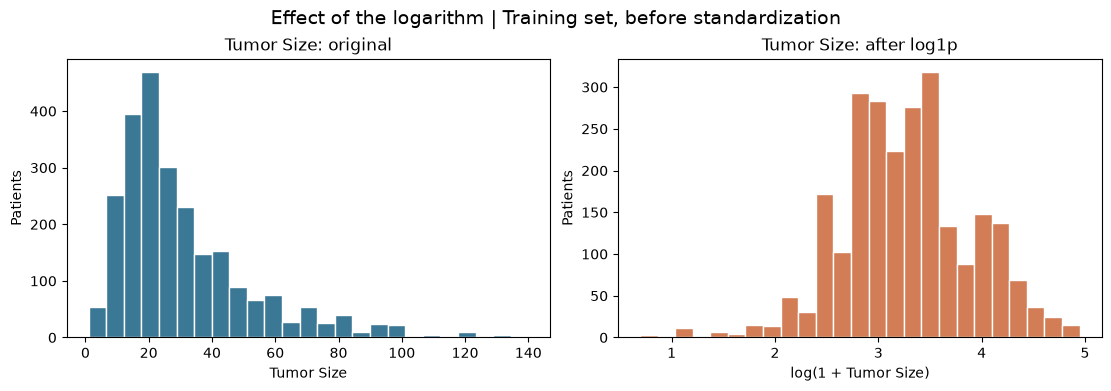

In [ ]:
log_skewness = pd.DataFrame({
    "Original skewness": X_train_model[LOG_NUM_COLS].skew(),
    "After log1p skewness": np.log1p(X_train_model[LOG_NUM_COLS]).skew(),
})
display(log_skewness.round(3))

fig, axes = plt.subplots(len(LOG_NUM_COLS), 2, figsize=(11, 3.8 * len(LOG_NUM_COLS)),
                         layout="constrained", squeeze=False)
for row, column in enumerate(LOG_NUM_COLS):
    values = X_train_model[column]
    axes[row, 0].hist(values, bins=25, color="#3b7896", edgecolor="white")
    axes[row, 0].set(title=f"{column}: original", xlabel=column, ylabel="Patients")
    axes[row, 1].hist(np.log1p(values), bins=25, color="#d27d55", edgecolor="white")
    axes[row, 1].set(title=f"{column}: after log1p", xlabel=f"log(1 + {column})", ylabel="Patients")
fig.suptitle("Effect of the logarithm | Training set, before standardization", fontsize=14)
plt.show()


**Modeling note:** Ordinal encoding preserves the order of T Stage, N Stage and Grade, but in a linear model a one-step increase is assumed to have the same effect across levels. This is a modeling assumption to consider when interpreting results. The other categorical features use one-hot encoding without dropping a reference level; consider a reference category if readily interpretable linear-model coefficients are needed.


## 12. Next Steps

Build model pipelines with fresh preprocessors and use `X_train_model` with `y_train` for development. When the final model has been selected, create the test feature table with `prepare_model_features(X_test)` and apply the fitted pipeline for final evaluation. For future patients, apply the same preparation function before using the model; alternatively, incorporate it into the model pipeline.


## 13. Model Pipelines: Logistic Regression, Decision Tree and Random Forest

We define three model pipelines. Logistic regression is a linear classifier whose coefficients can later be examined. A decision tree represents decisions as splits and can model nonlinear relationships. A random forest combines many trees and can capture more complex relationships, but is less directly interpretable than a single tree. Explainability, fairness and clinical interpretation require separate assessment for all models.

Each pipeline contains a fresh preprocessor and use `X_train_model`. The following grid search chooses model-specific hyperparameters, including whether to use balanced class weights. Scaling is generally unnecessary for a tree, but we initially use the same preprocessing for a consistent comparison. No model is trained or evaluated in this cell.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Create model pipelines; the grid search below chooses their hyperparameters.
model_pipelines = {
    "Logistic Regression": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", LogisticRegression(max_iter=2000, random_state=SEED)),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", DecisionTreeClassifier(random_state=SEED)),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor()),
        # Fix the number of trees for this first comparison; tune their size below.
        ("model", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1)),
    ]),
}

print("Models to tune:", ", ".join(model_pipelines))
print("Training patients:", len(X_train_model), "| Model input features:", X_train_model.shape[1])


Models to tune: Logistic Regression, Decision Tree, Random Forest
Training patients: 2452 | Model input features: 12


## 14. Hyperparameter Tuning with GridSearchCV

We tune each model separately using the same five stratified training folds and **average precision** as the selection metric. Average precision summarizes the precision–recall curve across thresholds and is useful when class 1 is less frequent. The training-set class 1 prevalence is about 13.7%, a rough reference for an uninformative ranking. We still report recall, precision, F1, balanced accuracy and ROC AUC to understand trade-offs.

We also report **precision** (how many predicted class 1 cases are correct), **recall** (how many true class 1 cases are identified), **F1** (their harmonic mean), **balanced accuracy** (mean recall across classes), **specificity** (recall for class 0) and **ROC AUC** (a ranking summary across thresholds). Precision, recall, F1, balanced accuracy and specificity use the model's default classification threshold; average precision and ROC AUC use prediction scores.

The search compares only the values listed below, so “best” means best **within this grid**, according to mean cross-validation average precision. These grids are exploratory starting points:

- **Logistic regression:** four regularization strengths (`C`) and whether to use balanced class weights. Smaller `C` means stronger regularization.
- **Decision tree:** three maximum depths, three minimum leaf sizes and whether to use balanced class weights. Limiting depth and leaf size can reduce overfitting.
- **Random forest:** 100 trees with two maximum depths, two minimum leaf sizes and whether to use balanced class weights. This modest grid keeps the first comparison manageable.

Each candidate is a pipeline containing a fresh preprocessor, fitted separately in each training fold. The positive-node ratio is a fixed row-wise calculation performed before the split into folds and does not learn information from other patients. When the grid search finishes, `refit` fits the selected pipeline on all training data. No held-out test data are used in the search.


In [ ]:
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, confusion_matrix

# Evaluate several metrics, while average precision selects the best configuration.
scoring = {
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "Balanced accuracy": "balanced_accuracy",
    "Specificity": make_scorer(recall_score, pos_label=0, zero_division=0),
    "ROC AUC": "roc_auc",
    "Average precision": "average_precision",
}

parameter_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1.0, 10.0],
        "model__class_weight": [None, "balanced"],
    },
    "Decision Tree": {
        "model__max_depth": [2, 4, 6],
        "model__min_samples_leaf": [10, 25, 50],
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__max_depth": [4, 8],
        "model__min_samples_leaf": [5, 20],
        "model__class_weight": [None, "balanced"],
    },
}

grid_searches = {}
for model_name, pipeline in model_pipelines.items():
    # The same scoring dictionary and stratified folds are used for both models.
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grids[model_name],
        scoring=scoring,
        refit="Average precision",
        cv=cv,
        n_jobs=1,
        error_score="raise",
        return_train_score=False,
    )
    search.fit(X_train_model, y_train)
    grid_searches[model_name] = search
    print(f"{model_name}: {len(search.cv_results_['params'])} parameter combinations")
    print("  Best parameters:", search.best_params_)
    print(f"  Best mean training-fold average precision: {search.best_score_:.3f}")


Logistic Regression: 8 parameter combinations
  Best parameters: {'model__C': 0.1, 'model__class_weight': None}
  Best mean training-fold average precision: 0.399
Decision Tree: 18 parameter combinations
  Best parameters: {'model__class_weight': None, 'model__max_depth': 6, 'model__min_samples_leaf': 25}
  Best mean training-fold average precision: 0.309
Random Forest: 8 parameter combinations
  Best parameters: {'model__class_weight': None, 'model__max_depth': 4, 'model__min_samples_leaf': 20}
  Best mean training-fold average precision: 0.391


### 14.1 Inspect the Search Results

The first table lists every tested configuration, ordered by mean average precision within each model. The second table and the heatmap report metrics for each model’s selected configuration. Precision, recall, F1, balanced accuracy and specificity use the default prediction threshold; average precision and ROC AUC summarize ranking across thresholds. Fold standard deviation shows variability between folds; it is not a confidence interval.

These selected cross-validation scores can be optimistic because the same folds were used to choose hyperparameters. They support development and comparison, not a final unbiased performance claim. We must also consider error types, model complexity, explainability and fairness; the highest average precision alone does not settle all of these questions.



Logistic Regression: all configurations


,Parameters,Mean average precision,Fold standard deviation
0,"{'model__C': 0.1, 'model__class_weight': None}",0.399,0.055
1,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.397,0.053
2,"{'model__C': 0.01, 'model__class_weight': None}",0.397,0.051
3,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.397,0.052
4,"{'model__C': 1.0, 'model__class_weight': None}",0.394,0.052
5,"{'model__C': 10.0, 'model__class_weight': None}",0.393,0.052
6,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.393,0.052
7,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.393,0.053



Decision Tree: all configurations


,Parameters,Mean average precision,Fold standard deviation
0,"{'model__class_weight': None, 'model__max_dept...",0.309,0.042
1,"{'model__class_weight': None, 'model__max_dept...",0.301,0.033
2,"{'model__class_weight': None, 'model__max_dept...",0.300,0.017
3,"{'model__class_weight': None, 'model__max_dept...",0.300,0.023
4,"{'model__class_weight': None, 'model__max_dept...",0.295,0.028
5,"{'model__class_weight': None, 'model__max_dept...",0.289,0.018
6,"{'model__class_weight': 'balanced', 'model__ma...",0.285,0.029
7,"{'model__class_weight': 'balanced', 'model__ma...",0.282,0.048
8,"{'model__class_weight': 'balanced', 'model__ma...",0.282,0.042
9,"{'model__class_weight': 'balanced', 'model__ma...",0.278,0.036



Random Forest: all configurations


,Parameters,Mean average precision,Fold standard deviation
0,"{'model__class_weight': None, 'model__max_dept...",0.391,0.062
1,"{'model__class_weight': None, 'model__max_dept...",0.389,0.069
2,"{'model__class_weight': 'balanced', 'model__ma...",0.385,0.059
3,"{'model__class_weight': None, 'model__max_dept...",0.385,0.055
4,"{'model__class_weight': 'balanced', 'model__ma...",0.381,0.057
5,"{'model__class_weight': 'balanced', 'model__ma...",0.377,0.065
6,"{'model__class_weight': None, 'model__max_dept...",0.365,0.056
7,"{'model__class_weight': 'balanced', 'model__ma...",0.361,0.063


Selected configuration for each model: cross-validation metrics


,Model,Metric,Mean,Fold standard deviation
0,Logistic Regression,Precision,0.624,0.093
1,Logistic Regression,Recall,0.142,0.042
2,Logistic Regression,F1,0.229,0.058
3,Logistic Regression,Balanced accuracy,0.564,0.020
4,Logistic Regression,Specificity,0.986,0.005
5,Logistic Regression,ROC AUC,0.765,0.023
6,Logistic Regression,Average precision,0.399,0.055
7,Decision Tree,Precision,0.417,0.079
8,Decision Tree,Recall,0.154,0.070
9,Decision Tree,F1,0.215,0.083


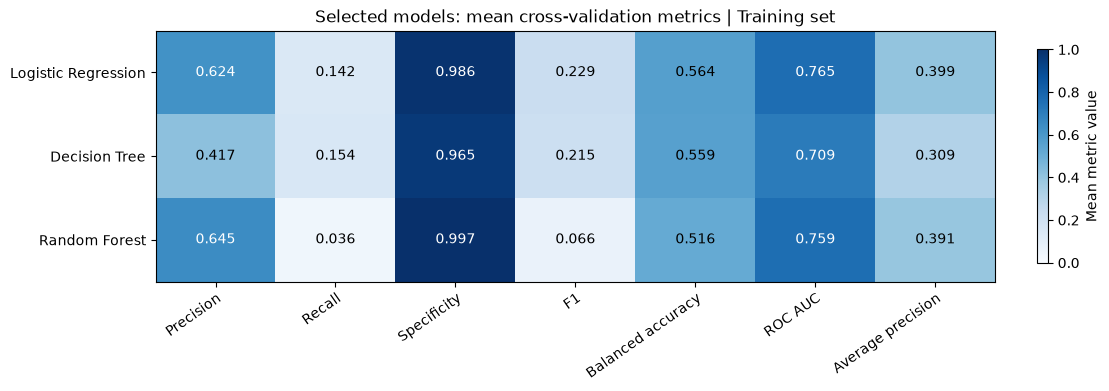

In [ ]:
candidate_tables = {}
selected_rows = []
for model_name, search in grid_searches.items():
    results = pd.DataFrame(search.cv_results_)
    candidates = results[["params", "mean_test_Average precision", "std_test_Average precision"]].copy()
    candidates = candidates.rename(columns={
        "params": "Parameters", "mean_test_Average precision": "Mean average precision",
        "std_test_Average precision": "Fold standard deviation",
    }).sort_values("Mean average precision", ascending=False).reset_index(drop=True)
    candidate_tables[model_name] = candidates
    print(f"\n{model_name}: all configurations")
    display(candidates.round(3))

    best = search.best_index_
    for metric_name in scoring:
        selected_rows.append({
            "Model": model_name, "Metric": metric_name,
            "Mean": results.loc[best, f"mean_test_{metric_name}"],
            "Fold standard deviation": results.loc[best, f"std_test_{metric_name}"],
        })

selected_model_comparison = pd.DataFrame(selected_rows)
print("Selected configuration for each model: cross-validation metrics")
display(selected_model_comparison.round(3))

# Heatmap of mean scores for the selected configuration of each model.
metric_order = ["Precision", "Recall", "Specificity", "F1", "Balanced accuracy", "ROC AUC", "Average precision"]
metric_heatmap = selected_model_comparison.pivot(index="Model", columns="Metric", values="Mean")
metric_heatmap = metric_heatmap.loc[list(model_pipelines), metric_order]
fig, ax = plt.subplots(figsize=(11, 3.8), layout="constrained")
image = ax.imshow(metric_heatmap.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(metric_order)), metric_order, rotation=35, ha="right", rotation_mode="anchor")
ax.set_yticks(range(len(metric_heatmap)), metric_heatmap.index)
for row in range(metric_heatmap.shape[0]):
    for col in range(metric_heatmap.shape[1]):
        value = metric_heatmap.iat[row, col]
        ax.text(col, row, f"{value:.3f}", ha="center", va="center", color="white" if value > 0.58 else "black")
ax.set_title("Selected models: mean cross-validation metrics | Training set")
fig.colorbar(image, ax=ax, label="Mean metric value", shrink=0.85)
plt.show()


### 14.2 Explore the Decision Threshold on Training Data

A model produces scores, but a classification decision also requires a threshold. Below, we generate out-of-fold scores for the selected configuration of each model and inspect illustrative thresholds of 0.10, 0.20, 0.30, 0.50 and 0.70. These values are **examples**, not a decision about a clinically appropriate threshold. The table reports false positives and false negatives as well as precision, recall and F1.

The scores are generated out of fold, but the hyperparameters were selected using all training folds first; therefore these results are conditional on that selection and may be optimistic. Class weighting can affect probability calibration, so do not interpret the scores as reliable individual probabilities without a separate calibration assessment. Threshold selection, if undertaken, must use training data and be justified before the final test evaluation.


,Model,Threshold,Precision,Recall,F1,False positives,False negatives
0,Logistic Regression,0.1,0.233,0.751,0.356,833,84
1,Logistic Regression,0.2,0.339,0.507,0.407,333,166
2,Logistic Regression,0.3,0.440,0.306,0.361,131,234
3,Logistic Regression,0.5,0.623,0.142,0.232,29,289
4,Logistic Regression,0.7,0.812,0.039,0.074,3,324
5,Decision Tree,0.1,0.222,0.682,0.336,804,107
6,Decision Tree,0.2,0.292,0.504,0.370,412,167
7,Decision Tree,0.3,0.342,0.341,0.342,221,222
8,Decision Tree,0.5,0.389,0.166,0.233,88,281
9,Decision Tree,0.7,0.400,0.018,0.034,9,331


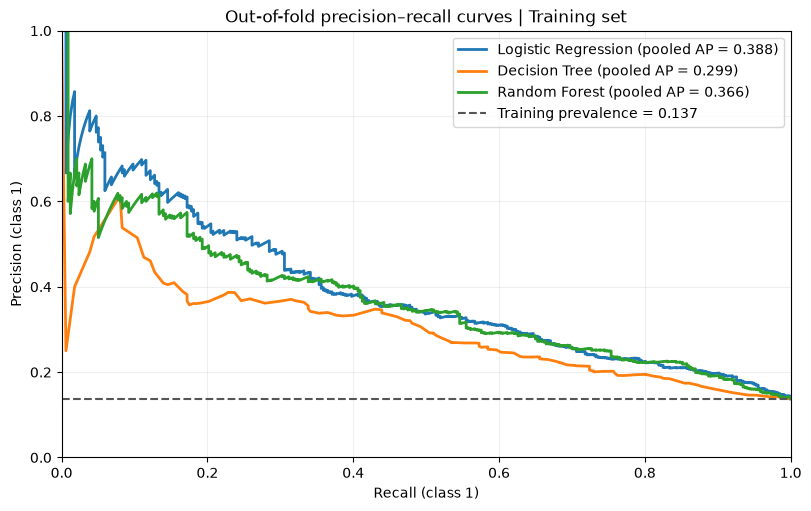

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# These out-of-fold scores use the chosen hyperparameters; no test data are used.
tuned_oof_scores = {}
threshold_rows = []
for model_name, search in grid_searches.items():
    scores = cross_val_predict(search.best_estimator_, X_train_model, y_train,
                               cv=cv, method="predict_proba")[:, 1]
    tuned_oof_scores[model_name] = scores
    for threshold in [0.10, 0.20, 0.30, 0.50, 0.70]:
        predictions = (scores >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()
        threshold_rows.append({
            "Model": model_name, "Threshold": threshold,
            "Precision": precision_score(y_train, predictions, zero_division=0),
            "Recall": recall_score(y_train, predictions, zero_division=0),
            "F1": f1_score(y_train, predictions, zero_division=0),
            "False positives": fp, "False negatives": fn,
        })

threshold_comparison = pd.DataFrame(threshold_rows)
display(threshold_comparison.round(3))

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
for model_name, scores in tuned_oof_scores.items():
    precision, recall, _ = precision_recall_curve(y_train, scores)
    pooled_ap = average_precision_score(y_train, scores)
    ax.plot(recall, precision, linewidth=2, label=f"{model_name} (pooled AP = {pooled_ap:.3f})")
ax.axhline(y_train.mean(), color="#555555", linestyle="--", label=f"Training prevalence = {y_train.mean():.3f}")
ax.set(xlabel="Recall (class 1)", ylabel="Precision (class 1)",
       title="Out-of-fold precision–recall curves | Training set", xlim=(0, 1), ylim=(0, 1))
ax.grid(alpha=0.2)
ax.legend(loc="upper right")
plt.show()


### 14.3 Exploratory F1-Based Thresholds

For each selected model, find the threshold that maximizes F1 on the out-of-fold training scores. This is a **working example**, not a clinically established threshold: F1 does not express the clinical costs of errors or establish fairness. The same training data informed both hyperparameter and threshold choices, so these metrics are optimistic; a separate validation strategy such as nested cross-validation is needed for a less biased development estimate. No threshold is declared final here.


In [ ]:
exploratory_f1_thresholds = {}
f1_threshold_rows = []
for model_name, scores in tuned_oof_scores.items():
    precision, recall, thresholds = precision_recall_curve(y_train, scores)
    # precision and recall have one extra endpoint without an associated threshold.
    numerator = 2 * precision[:-1] * recall[:-1]
    denominator = precision[:-1] + recall[:-1]
    f1_values = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator != 0)
    best_index = int(np.argmax(f1_values))
    threshold = float(thresholds[best_index])
    exploratory_f1_thresholds[model_name] = threshold
    predictions = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()
    f1_threshold_rows.append({"Model": model_name, "Exploratory threshold": threshold,
                              "Precision": precision_score(y_train, predictions, zero_division=0),
                              "Recall": recall_score(y_train, predictions, zero_division=0),
                              "F1": f1_score(y_train, predictions, zero_division=0),
                              "False positives": fp, "False negatives": fn})
exploratory_f1_comparison = pd.DataFrame(f1_threshold_rows)
display(exploratory_f1_comparison.round(3))


,Model,Exploratory threshold,Precision,Recall,F1,False positives,False negatives
0,Logistic Regression,0.187,0.333,0.546,0.413,369,153
1,Decision Tree,0.262,0.346,0.439,0.387,280,189
2,Random Forest,0.190,0.343,0.540,0.419,349,155


### 14.4 Out-of-Fold Confusion Matrices at the Default Threshold

Rows show observed outcomes and columns show predicted classes. Class 1 represents death before five years. The matrices use the selected configurations and the models’ default binary decision rule (score greater than 0.5 for class 1; a tie is class 0). They summarize out-of-fold training predictions, not test results. Because hyperparameters were selected using the same training folds, the counts may be optimistic.


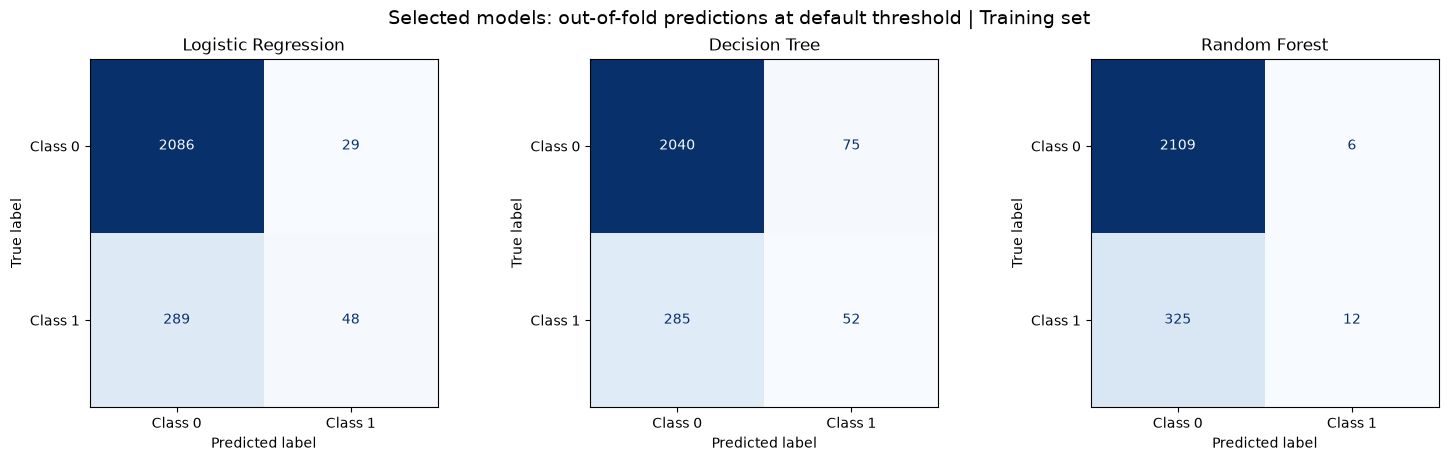

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(tuned_oof_scores), figsize=(15, 4.5), layout="constrained")
oof_confusion_matrices = {}
for ax, (model_name, scores) in zip(np.atleast_1d(axes), tuned_oof_scores.items()):
    predictions = (scores > 0.5).astype(int)  # Binary argmax assigns an exact tie to class 0.
    matrix = confusion_matrix(y_train, predictions, labels=[0, 1])
    oof_confusion_matrices[model_name] = matrix
    ConfusionMatrixDisplay(matrix, display_labels=["Class 0", "Class 1"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d"
    )
    ax.set_title(model_name)
fig.suptitle("Selected models: out-of-fold predictions at default threshold | Training set", fontsize=14)
plt.show()


### 14.5 Next Decisions

Discuss the selected configurations and threshold trade-offs before choosing a model. Any F1-based threshold below is exploratory, selected on the same training predictions and not a clinically validated decision. If model choices or mitigation are changed after explainability and fairness analyses, perform those comparisons on training data. Once the full approach is fixed, evaluate it once on the held-out test set. No subgroup fairness or clinical-validity conclusion follows from the grid search alone.


## 15. Compare Grid Search Selection Metrics: Average Precision vs F1

The previous grid searches selected each model's hyperparameters using **mean average precision**. Here we repeat the same search and use **mean F1 for class 1** instead. The model pipelines, parameter grids, five stratified folds and other reported metrics remain the same, so the selection criterion is the main change.

F1 combines precision and recall at the model's default decision rule (normally a 0.5 threshold). It does not specify the clinical costs of false positives and false negatives. Average precision summarizes ranking across thresholds. A higher F1 at the default threshold does not by itself prove a better clinical or fairer model. The threshold itself is **not tuned** in this search.

Both searches use only the training set, and the fitted preprocessors remain inside each pipeline. Model and feature decisions were informed by these data; using the same folds for hyperparameter selection and reporting can yield optimistic estimates. The held-out test set is still reserved for final evaluation.


In [ ]:
# Run a separate grid search for each model, selecting by F1 instead of average precision.
f1_grid_searches = {}
for model_name, pipeline in model_pipelines.items():
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grids[model_name],
        scoring=scoring,
        refit="F1",  # The highest mean validation-fold F1 selects the configuration.
        cv=cv,       # Reuse the same fixed stratified training folds.
        n_jobs=1,
        error_score="raise",
        return_train_score=False,
    )
    search.fit(X_train_model, y_train)
    f1_grid_searches[model_name] = search
    print(f"{model_name}: {len(search.cv_results_['params'])} parameter combinations")
    print("  Best parameters by F1:", search.best_params_)
    print(f"  Best mean training-fold F1: {search.best_score_:.3f}")


Logistic Regression: 8 parameter combinations
  Best parameters by F1: {'model__C': 0.1, 'model__class_weight': 'balanced'}
  Best mean training-fold F1: 0.399
Decision Tree: 18 parameter combinations
  Best parameters by F1: {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 50}
  Best mean training-fold F1: 0.363
Random Forest: 8 parameter combinations
  Best parameters by F1: {'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 5}
  Best mean training-fold F1: 0.398


### 15.1 Selected Configurations and Their Metrics

For each model, compare the configuration selected by average precision with the one selected by F1. Both sets of results come from the same training folds. Precision, recall, F1, specificity and balanced accuracy use the default decision threshold; average precision and ROC AUC evaluate ranking over thresholds. Fold means can differ slightly from metrics calculated from all out-of-fold predictions pooled together.


In [ ]:
metric_selection_rows = []
selected_parameter_rows = []
selection_searches = {
    "Average precision": grid_searches,
    "F1": f1_grid_searches,
}
for model_name in model_pipelines:
    for selection_metric, searches in selection_searches.items():
        search = searches[model_name]
        result = search.cv_results_
        best = search.best_index_
        selected_parameter_rows.append({"Model": model_name, "Selected by": selection_metric,
                                        "Best parameters": str(search.best_params_)})
        row = {"Model": model_name, "Selected by": selection_metric}
        for metric in ["Precision", "Recall", "F1", "Specificity", "Balanced accuracy", "ROC AUC", "Average precision"]:
            row[metric] = result[f"mean_test_{metric}"][best]
        metric_selection_rows.append(row)

selection_parameters = pd.DataFrame(selected_parameter_rows)
metric_selection_comparison = pd.DataFrame(metric_selection_rows)
print("Selected parameters for each model and criterion:")
display(selection_parameters)
print("Mean metrics across the same five validation folds:")
display(metric_selection_comparison.round(3))


Selected parameters for each model and criterion:


,Model,Selected by,Best parameters
0,Logistic Regression,Average precision,"{'model__C': 0.1, 'model__class_weight': None}"
1,Logistic Regression,F1,"{'model__C': 0.1, 'model__class_weight': 'bala..."
2,Decision Tree,Average precision,"{'model__class_weight': None, 'model__max_dept..."
3,Decision Tree,F1,"{'model__class_weight': 'balanced', 'model__ma..."
4,Random Forest,Average precision,"{'model__class_weight': None, 'model__max_dept..."
5,Random Forest,F1,"{'model__class_weight': 'balanced', 'model__ma..."


Mean metrics across the same five validation folds:


,Model,Selected by,Precision,Recall,F1,Specificity,Balanced accuracy,ROC AUC,Average precision
0,Logistic Regression,Average precision,0.624,0.142,0.229,0.986,0.564,0.765,0.399
1,Logistic Regression,F1,0.286,0.662,0.399,0.733,0.698,0.764,0.397
2,Decision Tree,Average precision,0.417,0.154,0.215,0.965,0.559,0.709,0.309
3,Decision Tree,F1,0.251,0.665,0.363,0.681,0.673,0.710,0.285
4,Random Forest,Average precision,0.645,0.036,0.066,0.997,0.516,0.759,0.391
5,Random Forest,F1,0.303,0.582,0.398,0.785,0.683,0.748,0.361


### 15.2 Precision, Recall and F1 by Selection Criterion

These bars compare mean fold metrics at the default threshold. They illustrate whether selecting hyperparameters by F1 trades precision for recall compared with selecting by average precision. They do not establish the best threshold, subgroup fairness or clinical utility.


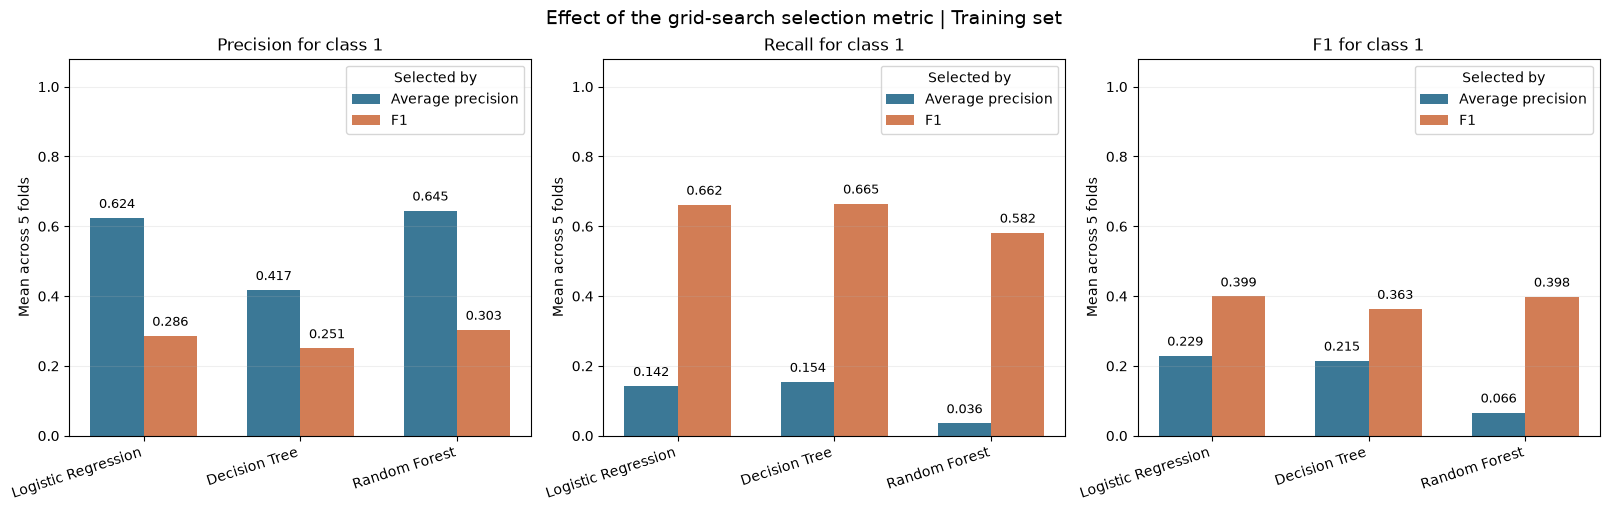

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), layout="constrained")
models_for_comparison = list(model_pipelines)
positions = np.arange(len(models_for_comparison))
width = 0.34
for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    for offset, criterion, color in [(-width / 2, "Average precision", "#3b7896"),
                                     (width / 2, "F1", "#d27d55")]:
        values = (metric_selection_comparison[metric_selection_comparison["Selected by"] == criterion]
                  .set_index("Model").loc[models_for_comparison, metric])
        bars = ax.bar(positions + offset, values, width, label=criterion, color=color)
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02,
                    f"{value:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(positions, models_for_comparison, rotation=18, ha="right")
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("Mean across 5 folds")
    ax.set_title(metric + " for class 1")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(title="Selected by")
fig.suptitle("Effect of the grid-search selection metric | Training set", fontsize=14)
plt.show()


### 15.3 Out-of-Fold Error Counts for the Selected Configurations

For each of the six selected configurations, obtain one out-of-fold class prediction per training patient at the default threshold. A **false negative** is a class 1 patient predicted as class 0; a **false positive** is a class 0 patient predicted as class 1. These are development comparisons, not independent final-test results: hyperparameters were selected using these training folds. Increasing recall can also increase false positives, so inspect both counts along with the other metrics.


In [ ]:
selection_error_rows = []
selection_oof_predictions = {}
for model_name in model_pipelines:
    for selection_metric, searches in selection_searches.items():
        search = searches[model_name]
        # Refit the chosen pipeline in each fold to obtain one held-out prediction per patient.
        predictions = cross_val_predict(search.best_estimator_, X_train_model, y_train,
                                        cv=cv, method="predict")
        selection_oof_predictions[(model_name, selection_metric)] = predictions
        tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()
        selection_error_rows.append({"Model": model_name, "Selected by": selection_metric,
                                     "True positives": tp, "False negatives": fn,
                                     "False positives": fp, "True negatives": tn})
selection_errors = pd.DataFrame(selection_error_rows)
display(selection_errors)


,Model,Selected by,True positives,False negatives,False positives,True negatives
0,Logistic Regression,Average precision,48,289,29,2086
1,Logistic Regression,F1,223,114,564,1551
2,Decision Tree,Average precision,52,285,75,2040
3,Decision Tree,F1,224,113,675,1440
4,Random Forest,Average precision,12,325,6,2109
5,Random Forest,F1,196,141,455,1660


### 15.4 Interpretation and Next Steps

Compare the chosen parameters and the pattern of errors for the two selection criteria rather than assuming that one metric is universally best. If F1 increases recall, check how precision and the number of false positives change. F1 optimization does not replace threshold analysis, explainability or a fairness assessment; results can differ between subgroups and can be uncertain for small groups. Final model and threshold decisions should be fixed before the held-out test set is evaluated.


## 16. ROC and Threshold Analysis: Logistic Regression Selected by F1

We explore the F1-selected logistic regression as a provisional candidate. Its model configuration is fixed here; we vary only the threshold applied to its scores. Class **1** means death before five years and class **0** means observed survival of at least five years.

The **ROC curve** shows the true positive rate (TPR, or recall) against the false positive rate (FPR) as the threshold changes. **ROC AUC** summarizes ranking across thresholds; it does not select a threshold and is not the proportion of correct predictions.

We also find the threshold with the highest *pooled out-of-fold* balanced accuracy on the training data. Balanced accuracy is the average of class 1 recall and class 0 recall (specificity = 1 − FPR); it weights the two class recalls equally, not the clinical costs of individual errors. The candidate is exploratory: hyperparameters and threshold were selected using the same training data, so the result may be optimistic. A less biased assessment can use nested cross-validation or a separate validation set within training. **No threshold is declared final and no held-out test predictions are made here.**

Because the selected model uses class weights, scores should not be interpreted as reliable individual probabilities without a separate calibration assessment.


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, balanced_accuracy_score

# Use the F1-selected logistic configuration; refit within each training fold.
logistic_f1_model = f1_grid_searches["Logistic Regression"].best_estimator_
logistic_f1_oof_scores = cross_val_predict(
    logistic_f1_model, X_train_model, y_train, cv=cv, method="predict_proba"
)[:, 1]

# The ROC curve evaluates all score thresholds. Its initial infinite threshold predicts no positives.
fpr_values, tpr_values, roc_thresholds = roc_curve(
    y_train, logistic_f1_oof_scores, drop_intermediate=False
)
finite = np.isfinite(roc_thresholds)
# Maximizing TPR - FPR is equivalent to maximizing balanced accuracy.
valid_indexes = np.flatnonzero(finite)
best_index = valid_indexes[np.argmax(tpr_values[finite] - fpr_values[finite])]
roc_ba_candidate = float(roc_thresholds[best_index])
pooled_roc_auc = roc_auc_score(y_train, logistic_f1_oof_scores)
print("F1-selected logistic parameters:", f1_grid_searches["Logistic Regression"].best_params_)
print(f"Pooled out-of-fold ROC AUC: {pooled_roc_auc:.3f}")
print(f"Exploratory threshold maximizing pooled balanced accuracy: {roc_ba_candidate:.4f}")


F1-selected logistic parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Pooled out-of-fold ROC AUC: 0.762
Exploratory threshold maximizing pooled balanced accuracy: 0.5029


### 16.1 Compare the Candidate with Illustrative Thresholds

The following table compares the candidate with 0.30, 0.40 and 0.50. Rates and counts are calculated from pooled out-of-fold predictions on the training set. Precision is included because even a moderate FPR can correspond to many false positives when class 0 is much larger. A threshold below or above 0.50 is not automatically better: the preferred trade-off depends on the intended use and the consequences of each error.


In [ ]:
threshold_diagnostics_rows = []
threshold_options = [("Illustrative", 0.30), ("Illustrative", 0.40),
                     ("Default", 0.50), ("Exploratory maximum balanced accuracy", roc_ba_candidate)]
for name, threshold in threshold_options:
    # Apply each threshold to the same out-of-fold scores; do not refit or use test data.
    predictions = (logistic_f1_oof_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()
    threshold_diagnostics_rows.append({
        "Threshold type": name, "Threshold": threshold,
        "Recall / TPR": tp / (tp + fn), "FPR": fp / (fp + tn),
        "Specificity": tn / (tn + fp),
        "Balanced accuracy": balanced_accuracy_score(y_train, predictions),
        "Precision": precision_score(y_train, predictions, zero_division=0),
        "F1": f1_score(y_train, predictions, zero_division=0),
        "True positives": tp, "False negatives": fn,
        "False positives": fp, "True negatives": tn,
    })
roc_threshold_comparison = pd.DataFrame(threshold_diagnostics_rows)
display(roc_threshold_comparison.round(3))


,Threshold type,Threshold,Recall / TPR,FPR,Specificity,Balanced accuracy,Precision,F1,True positives,False negatives,False positives,True negatives
0,Illustrative,0.300,0.908,0.603,0.397,0.653,0.194,0.319,306,31,1275,840
1,Illustrative,0.400,0.774,0.402,0.598,0.686,0.235,0.360,261,76,850,1265
2,Default,0.500,0.662,0.267,0.733,0.698,0.283,0.397,223,114,564,1551
3,Exploratory maximum balanced accuracy,0.503,0.659,0.263,0.737,0.698,0.285,0.398,222,115,557,1558


### 16.2 ROC Curve and Threshold Trade-Off

The left plot shows the pooled out-of-fold ROC curve and three illustrative operating points. A point closer to the top-left has higher TPR and lower FPR, but the curve does not determine how costly each error is. The right plot shows how TPR, FPR and balanced accuracy change with the threshold. The dashed line marks the exploratory balanced-accuracy candidate from these same training predictions.

The pooled out-of-fold ROC AUC can differ from the mean of the five fold-specific AUC values shown earlier: they aggregate predictions in different ways. The threshold selected on these predictions is a development result, not an independent validation or a clinical recommendation.


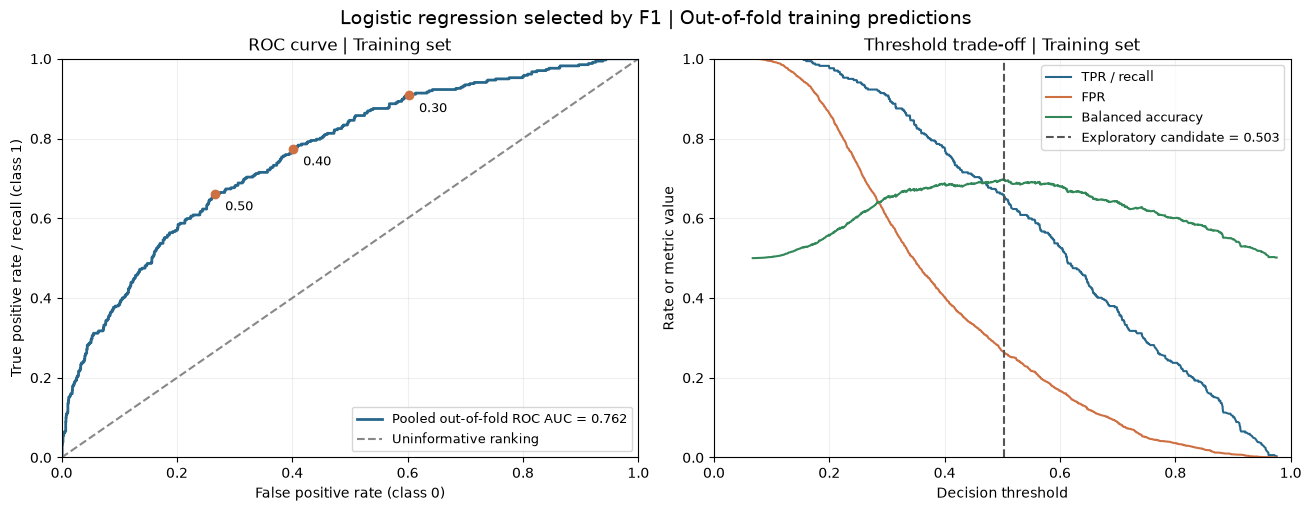

In [ ]:
fig, (ax_roc, ax_threshold) = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
ax_roc.plot(fpr_values, tpr_values, color="#27678b", linewidth=2,
            label=f"Pooled out-of-fold ROC AUC = {pooled_roc_auc:.3f}")
ax_roc.plot([0, 1], [0, 1], color="#888888", linestyle="--", label="Uninformative ranking")
for threshold in [0.30, 0.40, 0.50]:
    row = roc_threshold_comparison.loc[roc_threshold_comparison["Threshold"] == threshold].iloc[0]
    ax_roc.scatter(row["FPR"], row["Recall / TPR"], color="#cf7043", zorder=3)
    ax_roc.annotate(f"{threshold:.2f}", (row["FPR"], row["Recall / TPR"]),
                    xytext=(7, -12), textcoords="offset points", fontsize=9)
ax_roc.set(xlabel="False positive rate (class 0)", ylabel="True positive rate / recall (class 1)",
           title="ROC curve | Training set", xlim=(0, 1), ylim=(0, 1))
ax_roc.grid(alpha=0.2)
ax_roc.legend(loc="lower right", fontsize=9)

ax_threshold.plot(roc_thresholds[finite], tpr_values[finite], label="TPR / recall", color="#27678b")
ax_threshold.plot(roc_thresholds[finite], fpr_values[finite], label="FPR", color="#cf7043")
ax_threshold.plot(roc_thresholds[finite], (tpr_values[finite] + 1 - fpr_values[finite]) / 2,
                  label="Balanced accuracy", color="#328858")
ax_threshold.axvline(roc_ba_candidate, color="#555555", linestyle="--",
                     label=f"Exploratory candidate = {roc_ba_candidate:.3f}")
ax_threshold.set(xlabel="Decision threshold", ylabel="Rate or metric value",
                 title="Threshold trade-off | Training set", xlim=(0, 1), ylim=(0, 1))
ax_threshold.grid(alpha=0.2)
ax_threshold.legend(loc="best", fontsize=9)
fig.suptitle("Logistic regression selected by F1 | Out-of-fold training predictions", fontsize=14)
plt.show()


### 16.3 Interpretation and Next Step

Compare the candidate threshold with alternatives using **both** rates and patient counts. A balanced-accuracy optimum is not automatically a clinically appropriate threshold and does not guarantee fairness across groups. Before fixing a final model and threshold, assess their stability, explainability and subgroup performance using training data. Only then evaluate the fixed approach on the held-out test set.


## 17. Experiments

The following experiments investigate two alternatives to the main pipelines. They are intended for critical discussion and presentation, not as automatic replacements. Both use only the training set, the same stratified folds and the F1-selected model settings. Small differences should be interpreted cautiously because the model settings were selected using the same training data.


### 17.1 Experiment: Random Oversampling

We compare balanced class weights with random oversampling for each F1-selected model, keeping its other hyperparameters and the validation folds fixed. Oversampling repeats existing minority-class observations; it does not create independent patients. In each fold, the preprocessor is fitted on the original training portion, then `RandomOverSampler` balances that training portion before the model is fitted. Validation rows are never resampled. To isolate the two approaches, the oversampled model does not also use class weights.

The values below use the default classification rule. Average precision summarizes ranking across thresholds. The comparison is exploratory: hyperparameters were selected on the same training folds and were not retuned specifically for oversampling. It does not prove fairness or statistical superiority. The held-out test set is not used.

This experiment requires `imbalanced-learn`. If needed in a different notebook environment, run `%pip install imbalanced-learn` once and restart the kernel.


Mean metrics across five training folds:


,Model,Strategy,Precision,Recall,F1,Average precision
0,Logistic Regression,Balanced class weights,0.286,0.662,0.399,0.397
1,Logistic Regression,Random oversampling,0.282,0.650,0.393,0.391
2,Decision Tree,Balanced class weights,0.251,0.665,0.363,0.285
3,Decision Tree,Random oversampling,0.258,0.632,0.366,0.291
4,Random Forest,Balanced class weights,0.303,0.582,0.398,0.361
5,Random Forest,Random oversampling,0.316,0.534,0.397,0.344


Pooled out-of-fold error counts at the default threshold:


,Model,Strategy,True positives,False negatives,False positives,True negatives
0,Logistic Regression,Balanced class weights,223,114,564,1551
1,Logistic Regression,Random oversampling,219,118,565,1550
2,Decision Tree,Balanced class weights,224,113,675,1440
3,Decision Tree,Random oversampling,213,124,618,1497
4,Random Forest,Balanced class weights,196,141,455,1660
5,Random Forest,Random oversampling,180,157,391,1724


Training-fold sampling check; validation patients were not resampled:


,Fold,Class 0 before,Class 1 before,Class 0 after,Class 1 after,Validation patients unchanged
0,1,1692,269,1692,1692,491
1,2,1692,269,1692,1692,491
2,3,1692,270,1692,1692,490
3,4,1692,270,1692,1692,490
4,5,1692,270,1692,1692,490


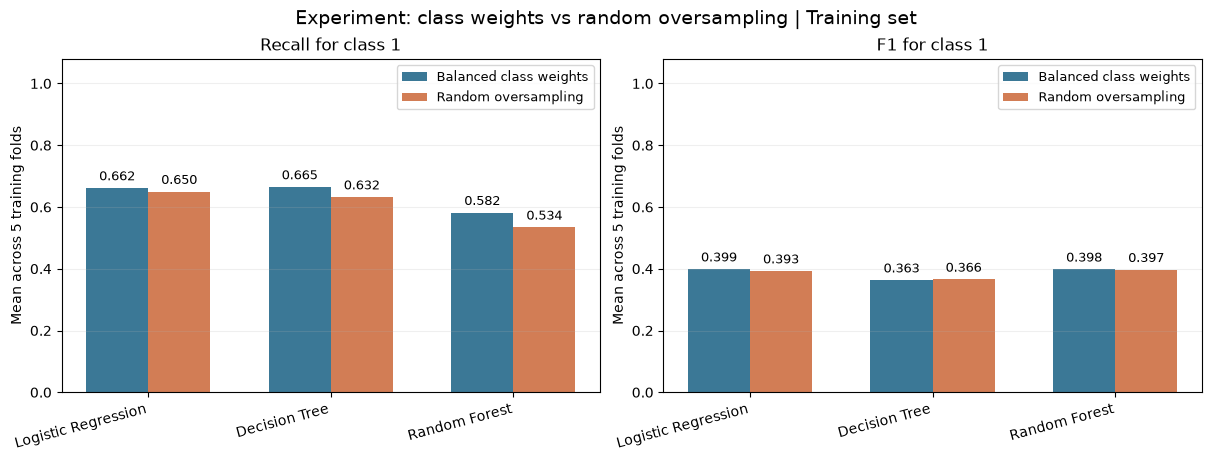

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from imblearn.pipeline import Pipeline as SamplingPipeline
from imblearn.over_sampling import RandomOverSampler

experiment_splits = list(cv.split(X_train_model, y_train))  # Identical training/validation rows for every comparison.
oversampling_results = []
oversampling_errors = []
oversampling_fold_checks = []
for model_name, search in f1_grid_searches.items():
    selected = search.best_estimator_
    # Keep all selected hyperparameters fixed; compare only the balancing strategy.
    for strategy in ["Balanced class weights", "Random oversampling"]:
        model = clone(selected.named_steps["model"])
        model.set_params(class_weight="balanced" if strategy == "Balanced class weights" else None)
        steps = [("preprocessor", clone(selected.named_steps["preprocessor"]))]
        if strategy == "Random oversampling":
            steps.append(("oversample", RandomOverSampler(random_state=SEED)))
        steps.append(("model", model))
        pipeline = SamplingPipeline(steps)
        scores = cross_validate(pipeline, X_train_model, y_train, cv=experiment_splits,
                                scoring=scoring, return_estimator=True, error_score="raise", n_jobs=1)
        row = {"Model": model_name, "Strategy": strategy}
        for metric in ["Precision", "Recall", "F1", "Average precision"]:
            row[metric] = scores[f"test_{metric}"].mean()
        oversampling_results.append(row)

        # One out-of-fold prediction per patient; sampling indices refer to training rows only.
        predictions = np.full(len(y_train), -1, dtype=int)
        visits = np.zeros(len(y_train), dtype=int)
        for fold, ((train_index, validation_index), fitted) in enumerate(zip(experiment_splits, scores["estimator"]), start=1):
            assert len(np.intersect1d(train_index, validation_index)) == 0
            predictions[validation_index] = fitted.predict(X_train_model.iloc[validation_index])
            visits[validation_index] += 1
            if strategy == "Random oversampling":
                sampled_indices = fitted.named_steps["oversample"].sample_indices_
                original = y_train.iloc[train_index]
                resampled = original.iloc[sampled_indices]
                assert np.max(sampled_indices) < len(train_index)
                assert (resampled == 0).sum() == (resampled == 1).sum()
                if model_name == "Logistic Regression":
                    oversampling_fold_checks.append({"Fold": fold,
                        "Class 0 before": int((original == 0).sum()), "Class 1 before": int((original == 1).sum()),
                        "Class 0 after": int((resampled == 0).sum()), "Class 1 after": int((resampled == 1).sum()),
                        "Validation patients unchanged": len(validation_index)})
        assert (visits == 1).all()
        tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()
        oversampling_errors.append({"Model": model_name, "Strategy": strategy,
                                    "True positives": tp, "False negatives": fn,
                                    "False positives": fp, "True negatives": tn})

oversampling_metrics = pd.DataFrame(oversampling_results)
oversampling_error_counts = pd.DataFrame(oversampling_errors)
print("Mean metrics across five training folds:")
display(oversampling_metrics.round(3))
print("Pooled out-of-fold error counts at the default threshold:")
display(oversampling_error_counts)
print("Training-fold sampling check; validation patients were not resampled:")
display(pd.DataFrame(oversampling_fold_checks))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
model_order = list(f1_grid_searches)
positions = np.arange(len(model_order))
width = 0.34
for ax, metric in zip(axes, ["Recall", "F1"]):
    for offset, strategy, color in [(-width / 2, "Balanced class weights", "#3b7896"),
                                    (width / 2, "Random oversampling", "#d27d55")]:
        values = oversampling_metrics[oversampling_metrics["Strategy"] == strategy].set_index("Model").loc[model_order, metric]
        bars = ax.bar(positions + offset, values, width, label=strategy, color=color)
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(positions, model_order, rotation=15, ha="right")
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("Mean across 5 training folds")
    ax.set_title(metric + " for class 1")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=9)
fig.suptitle("Experiment: class weights vs random oversampling | Training set", fontsize=14)
plt.show()


#### Reading the oversampling experiment

Compare precision, recall, F1 and false positives/negatives together. In the initial run, random oversampling did not provide a consistent improvement over balanced class weights: the logistic model's F1 was slightly lower; the tree's F1 was slightly higher but its recall was lower; and the random forest's F1 was almost unchanged. These small differences are not a statistical conclusion, and the comparison is conditional on the fixed F1-selected hyperparameters and a single random seed. Oversampling does not automatically improve fairness across demographic groups.


### 17.2 Experiment: Model-Specific Numerical Preprocessing

Logistic regression keeps the current numerical preprocessing: `log1p` followed by standardization for `Tumor Size`, and standardization for the other numerical features. Scale affects its coefficients and regularization. This experiment does not change the logistic regression pipeline.

Decision trees and random forests choose splits based mainly on the order of numerical values, so numerical scaling and a strictly increasing logarithm are often unnecessary. We compare their current preprocessing with a version that passes all numerical features through in their original scale, with **no logarithm or standardization**. The same ordered encoding for T Stage, N Stage and Grade and the same one-hot encoding for the other categorical features are retained.

The comparison keeps each F1-selected model's features, hyperparameters, class weights, default decision rule and the five training folds fixed. Different transformations can still lead to differences, for example around split boundaries or numerical ties; identical results are not guaranteed. Hyperparameters were selected using these same training folds, and were not retuned for the raw numerical version. Treat this as an exploratory comparison, not an independent estimate or final model selection. The held-out test set is not used.


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# Keep the original numerical column order while passing through unscaled values.
def make_tree_preprocessor():
    return ColumnTransformer([
        ("raw_tumor_size", "passthrough", LOG_NUM_COLS),
        ("raw_other_numerical", "passthrough", SCALE_ONLY_COLS),
        ("ord", OrdinalEncoder(categories=ORD_CATEGORIES), ORD_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), MODEL_CAT_COLS),
    ])

preprocessing_variants = {}
for model_name in ["Decision Tree", "Random Forest"]:
    selected_pipeline = f1_grid_searches[model_name].best_estimator_
    preprocessing_variants[model_name] = {
        "Current: log and scaling": clone(selected_pipeline),
        "Tree-specific: raw numerical": clone(selected_pipeline).set_params(
            preprocessor=make_tree_preprocessor()
        ),
    }
    print(f"{model_name} fixed parameters:", f1_grid_searches[model_name].best_params_)
print("Logistic Regression retains its existing preprocessing.")


Decision Tree fixed parameters: {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 50}
Random Forest fixed parameters: {'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 5}
Logistic Regression retains its existing preprocessing.


#### 17.2.1 Cross-Validation Metrics

Each row shows mean validation-fold metrics for one model and preprocessing version. Precision, recall, F1, specificity and balanced accuracy use the default decision rule; ROC AUC and average precision summarize score ranking across thresholds. The table of paired differences subtracts the current preprocessing score from the raw-numerical score **within each fold**. Fold variability is descriptive and is not a confidence interval.


In [ ]:
preprocessing_scores = {}
preprocessing_metric_rows = []
preprocessing_error_rows = []
preprocessing_oof_predictions = {}

for model_name, variants in preprocessing_variants.items():
    for variant_name, pipeline in variants.items():
        # Each entire pipeline is fitted only on the training part of its fold.
        scores = cross_validate(pipeline, X_train_model, y_train, cv=cv, scoring=scoring,
                                return_estimator=True, error_score="raise", n_jobs=1)
        preprocessing_scores[(model_name, variant_name)] = scores
        row = {"Model": model_name, "Preprocessing": variant_name}
        for metric in ["Precision", "Recall", "F1", "Specificity", "Balanced accuracy", "ROC AUC", "Average precision"]:
            row[metric] = scores[f"test_{metric}"].mean()
        preprocessing_metric_rows.append(row)

        # Every validation row receives a prediction from its own fitted fold model.
        predictions = np.full(len(y_train), -1, dtype=int)
        validation_visits = np.zeros(len(y_train), dtype=int)
        for (_, validation_index), fitted in zip(cv.split(X_train_model, y_train), scores["estimator"]):
            predictions[validation_index] = fitted.predict(X_train_model.iloc[validation_index])
            validation_visits[validation_index] += 1
        assert (validation_visits == 1).all()
        preprocessing_oof_predictions[(model_name, variant_name)] = predictions
        tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()
        preprocessing_error_rows.append({"Model": model_name, "Preprocessing": variant_name,
                                         "True positives": tp, "False negatives": fn,
                                         "False positives": fp, "True negatives": tn})

preprocessing_metrics = pd.DataFrame(preprocessing_metric_rows)
preprocessing_errors = pd.DataFrame(preprocessing_error_rows)
print("Mean metrics across five training folds:")
display(preprocessing_metrics.round(3))
print("Pooled out-of-fold error counts at the default decision threshold:")
display(preprocessing_errors)

paired_rows = []
for model_name in preprocessing_variants:
    current = preprocessing_scores[(model_name, "Current: log and scaling")]
    raw = preprocessing_scores[(model_name, "Tree-specific: raw numerical")]
    for metric in ["Precision", "Recall", "F1", "Average precision"]:
        difference = raw[f"test_{metric}"] - current[f"test_{metric}"]
        paired_rows.append({"Model": model_name, "Metric": metric,
                            "Mean difference (raw - current)": difference.mean(),
                            "Fold difference SD": difference.std()})
paired_preprocessing_differences = pd.DataFrame(paired_rows)
print("Paired differences across the same folds:")
display(paired_preprocessing_differences.round(3))


Mean metrics across five training folds:


,Model,Preprocessing,Precision,Recall,F1,Specificity,Balanced accuracy,ROC AUC,Average precision
0,Decision Tree,Current: log and scaling,0.251,0.665,0.363,0.681,0.673,0.710,0.285
1,Decision Tree,Tree-specific: raw numerical,0.251,0.665,0.363,0.681,0.673,0.710,0.285
2,Random Forest,Current: log and scaling,0.303,0.582,0.398,0.785,0.683,0.748,0.361
3,Random Forest,Tree-specific: raw numerical,0.302,0.579,0.397,0.785,0.682,0.748,0.362


Pooled out-of-fold error counts at the default decision threshold:


,Model,Preprocessing,True positives,False negatives,False positives,True negatives
0,Decision Tree,Current: log and scaling,224,113,675,1440
1,Decision Tree,Tree-specific: raw numerical,224,113,675,1440
2,Random Forest,Current: log and scaling,196,141,455,1660
3,Random Forest,Tree-specific: raw numerical,195,142,455,1660


Paired differences across the same folds:


,Model,Metric,Mean difference (raw - current),Fold difference SD
0,Decision Tree,Precision,0.000,0.000
1,Decision Tree,Recall,0.000,0.000
2,Decision Tree,F1,0.000,0.000
3,Decision Tree,Average precision,0.000,0.000
4,Random Forest,Precision,-0.001,0.002
5,Random Forest,Recall,-0.003,0.006
6,Random Forest,F1,-0.002,0.003
7,Random Forest,Average precision,0.001,0.001


#### 17.2.2 Visual Comparison

The bars show mean fold precision, recall and F1 for class 1 at the default threshold. A very small difference does not establish that one version is better; consider fold variation, the error counts, and the fact that the parameters were selected using these training folds. Average precision in the table summarizes ranking across thresholds.


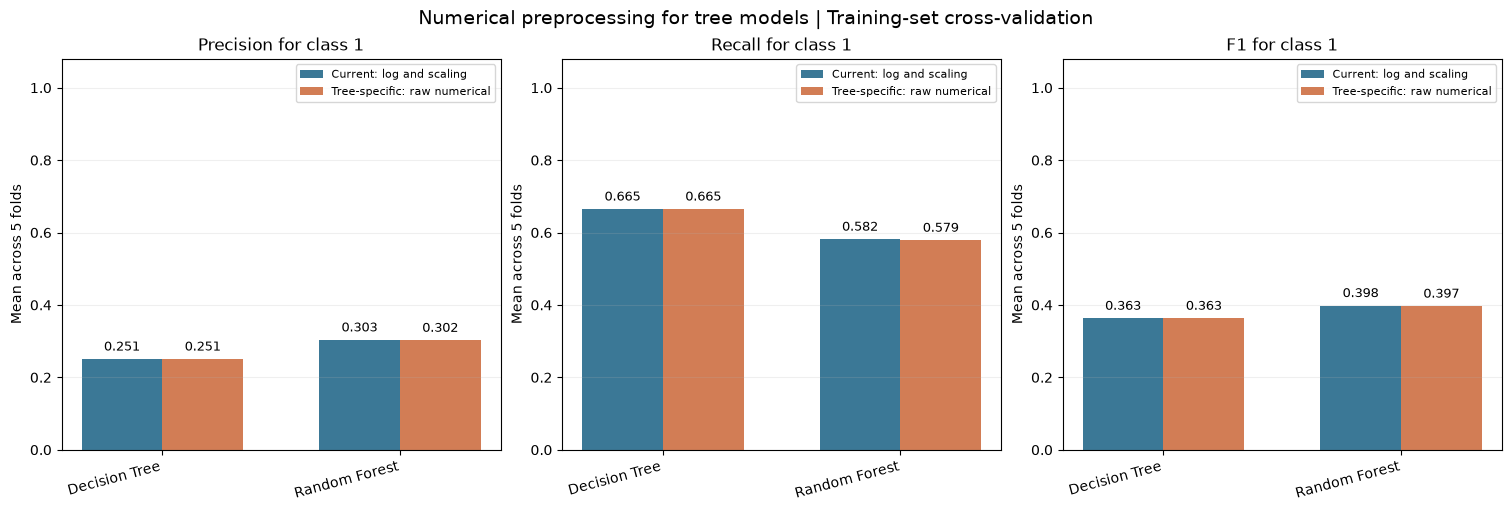

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
models = list(preprocessing_variants)
positions = np.arange(len(models))
width = 0.34
for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    for offset, variant, color in [(-width / 2, "Current: log and scaling", "#3b7896"),
                                    (width / 2, "Tree-specific: raw numerical", "#d27d55")]:
        values = (preprocessing_metrics[preprocessing_metrics["Preprocessing"] == variant]
                  .set_index("Model").loc[models, metric])
        bars = ax.bar(positions + offset, values, width, label=variant, color=color)
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015,
                    f"{value:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(positions, models, rotation=15, ha="right")
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("Mean across 5 folds")
    ax.set_title(metric + " for class 1")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("Numerical preprocessing for tree models | Training-set cross-validation", fontsize=14)
plt.show()


#### 17.2.3 Interpreting the Experiment

Compare both the fold means and pooled error counts before deciding which tree preprocessing to retain. If results are similar, simpler numerical passthrough can be justified by how tree splits work; this does not prove the approaches are identical for every new patient. If results differ, consider the size and consistency of the difference as well as explainability and subgroup behavior. The experiment does not evaluate fairness, does not retune hyperparameters and does not use the held-out test set. Any final preprocessing choice remains provisional until the broader model and fairness assessments are completed.

In the initial fixed-parameter run, the decision tree had the same F1 (0.363) with both approaches. The random forest F1 changed from 0.398 to 0.397, and its pooled false-negative count increased from 141 to 142. These results do not show a meaningful performance gain from removing the numerical transformations in this comparison.


### 17.3 Experiment: Partial Oversampling

The previous oversampling experiment used a 1:1 minority-to-majority ratio and fixed model settings. Here we test **0.25, 0.50, 0.75 and 1.00** as the minority-to-majority ratio after random oversampling. For example, 0.50 means one minority observation for every two majority observations, not 50% of all observations. Duplicated examples do not represent new independent patients.

For each of the three models, an F1-based grid search chooses the oversampling ratio and model hyperparameters together. The original F1 search with class weights is the comparator. Both use the same training folds, features and evaluation metrics. The oversampled pipeline uses no additional class weights, so these strategies are not combined. Each pipeline fits its preprocessor on the original training portion of a fold, then oversamples only that portion before fitting the model. Validation folds and the held-out test set are never resampled.

The results are exploratory: the same training folds are used for selection and reporting, and only one sampling seed is tested. F1 and other classification metrics use the default decision rule; threshold choice, probability calibration and fairness are separate questions. This experiment uses random oversampling only; it does not implement SMOTENC.


In [ ]:
# Compare partial and full random oversampling with the original class-weight search.
from sklearn.base import clone
from imblearn.pipeline import Pipeline as SamplingPipeline
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import GridSearchCV, cross_val_predict

sampling_ratios = [0.25, 0.50, 0.75, 1.00]  # Minority / majority after resampling.
partial_sampling_grids = {}
partial_sampling_parameter_grids = {}
for model_name, base_pipeline in model_pipelines.items():
    model = clone(base_pipeline.named_steps["model"]).set_params(class_weight=None)
    pipeline = SamplingPipeline([
        ("preprocessor", clone(base_pipeline.named_steps["preprocessor"])),
        ("oversample", RandomOverSampler(random_state=SEED)),
        ("model", model),
    ])
    # Reuse the original model grid, but do not combine oversampling with class weighting.
    grid = {key: value for key, value in parameter_grids[model_name].items()
            if key != "model__class_weight"}
    grid["oversample__sampling_strategy"] = sampling_ratios
    partial_sampling_parameter_grids[model_name] = grid
    search = GridSearchCV(pipeline, grid, scoring=scoring, refit="F1", cv=cv,
                          n_jobs=1, error_score="raise", return_train_score=False)
    search.fit(X_train_model, y_train)
    partial_sampling_grids[model_name] = search
    print(f"{model_name}: {len(search.cv_results_['params'])} configurations")
    print("  Best oversampling configuration:", search.best_params_)
    print(f"  Best mean training-fold F1: {search.best_score_:.3f}")


Logistic Regression: 16 configurations
  Best oversampling configuration: {'model__C': 0.1, 'oversample__sampling_strategy': 0.75}
  Best mean training-fold F1: 0.405
Decision Tree: 36 configurations
  Best oversampling configuration: {'model__max_depth': 4, 'model__min_samples_leaf': 25, 'oversample__sampling_strategy': 0.75}
  Best mean training-fold F1: 0.380
Random Forest: 16 configurations
  Best oversampling configuration: {'model__max_depth': 4, 'model__min_samples_leaf': 5, 'oversample__sampling_strategy': 0.75}
  Best mean training-fold F1: 0.417


#### 17.3.1 Best Configuration at Each Sampling Ratio

For each model and sampling ratio, the table shows the model-parameter combination with the highest mean validation-fold F1. Other metrics are shown to make the trade-off visible. A ratio is not automatically better because its F1 is slightly higher; fold variation and the selection process limit how confidently differences can be interpreted.


In [ ]:
partial_sampling_ratio_rows = []
for model_name, search in partial_sampling_grids.items():
    results = pd.DataFrame(search.cv_results_)
    for ratio in sampling_ratios:
        candidates = results[results["params"].map(lambda params: params["oversample__sampling_strategy"] == ratio)]
        best_index = candidates["mean_test_F1"].idxmax()
        best = results.loc[best_index]
        partial_sampling_ratio_rows.append({
            "Model": model_name, "Minority / majority": ratio,
            "Mean F1": best["mean_test_F1"], "F1 fold SD": best["std_test_F1"],
            "Mean recall": best["mean_test_Recall"], "Mean precision": best["mean_test_Precision"],
            "Mean average precision": best["mean_test_Average precision"],
            "Parameters": str(best["params"]),
        })
partial_sampling_ratio_results = pd.DataFrame(partial_sampling_ratio_rows)
display(partial_sampling_ratio_results.round(3))


,Model,Minority / majority,Mean F1,F1 fold SD,Mean recall,Mean precision,Mean average precision,Parameters
0,Logistic Regression,0.25,0.331,0.035,0.243,0.522,0.390,"{'model__C': 1.0, 'oversample__sampling_strate..."
1,Logistic Regression,0.50,0.394,0.042,0.415,0.375,0.396,"{'model__C': 0.1, 'oversample__sampling_strate..."
2,Logistic Regression,0.75,0.405,0.024,0.561,0.319,0.392,"{'model__C': 0.1, 'oversample__sampling_strate..."
3,Logistic Regression,1.00,0.397,0.026,0.659,0.285,0.394,"{'model__C': 0.01, 'oversample__sampling_strat..."
4,Decision Tree,0.25,0.273,0.082,0.222,0.386,0.292,"{'model__max_depth': 6, 'model__min_samples_le..."
5,Decision Tree,0.50,0.364,0.048,0.418,0.323,0.291,"{'model__max_depth': 4, 'model__min_samples_le..."
6,Decision Tree,0.75,0.380,0.040,0.531,0.297,0.286,"{'model__max_depth': 4, 'model__min_samples_le..."
7,Decision Tree,1.00,0.366,0.030,0.632,0.258,0.291,"{'model__max_depth': 6, 'model__min_samples_le..."
8,Random Forest,0.25,0.212,0.043,0.139,0.481,0.356,"{'model__max_depth': 8, 'model__min_samples_le..."
9,Random Forest,0.50,0.348,0.071,0.324,0.379,0.379,"{'model__max_depth': 8, 'model__min_samples_le..."


#### 17.3.2 Compare Selected Strategies and Overall Errors

Compare the best original F1 search (which chooses whether to use class weights) with the best oversampling search (which chooses the sampling ratio without class weights). The two strategies may select different model hyperparameters, so this compares **tuned strategies**, not the isolated effect of changing only one parameter.

Fold-average metrics are reported beside pooled out-of-fold error counts. The predictions are out of fold, but the hyperparameters were selected using these same training folds, so the estimates can be optimistic. The default threshold remains unchanged and no test-set prediction is made.


In [ ]:
partial_strategy_rows = []
partial_strategy_error_rows = []
partial_strategy_predictions = {}
strategy_searches = {"Class-weight search": f1_grid_searches,
                     "Oversampling search": partial_sampling_grids}

for model_name in model_pipelines:
    for strategy, searches in strategy_searches.items():
        search = searches[model_name]
        result = search.cv_results_
        index = search.best_index_
        row = {"Model": model_name, "Strategy": strategy, "Selected parameters": str(search.best_params_)}
        for metric in ["Precision", "Recall", "F1", "Specificity", "Balanced accuracy", "ROC AUC", "Average precision"]:
            row[metric] = result[f"mean_test_{metric}"][index]
        partial_strategy_rows.append(row)

        # Each training patient is predicted by a pipeline that did not fit that patient's fold.
        predictions = cross_val_predict(search.best_estimator_, X_train_model, y_train, cv=cv, method="predict")
        partial_strategy_predictions[(model_name, strategy)] = predictions
        tn, fp, fn, tp = confusion_matrix(y_train, predictions, labels=[0, 1]).ravel()
        partial_strategy_error_rows.append({"Model": model_name, "Strategy": strategy,
            "True positives": tp, "False negatives": fn, "False positives": fp, "True negatives": tn})

partial_strategy_metrics = pd.DataFrame(partial_strategy_rows)
partial_strategy_errors = pd.DataFrame(partial_strategy_error_rows)
print("Mean validation-fold metrics:")
display(partial_strategy_metrics.round(3))
print("Pooled out-of-fold error counts at the default threshold:")
display(partial_strategy_errors)


Mean validation-fold metrics:


,Model,Strategy,Selected parameters,Precision,Recall,F1,Specificity,Balanced accuracy,ROC AUC,Average precision
0,Logistic Regression,Class-weight search,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.286,0.662,0.399,0.733,0.698,0.764,0.397
1,Logistic Regression,Oversampling search,"{'model__C': 0.1, 'oversample__sampling_strate...",0.319,0.561,0.405,0.806,0.683,0.761,0.392
2,Decision Tree,Class-weight search,"{'model__class_weight': 'balanced', 'model__ma...",0.251,0.665,0.363,0.681,0.673,0.710,0.285
3,Decision Tree,Oversampling search,"{'model__max_depth': 4, 'model__min_samples_le...",0.297,0.531,0.380,0.799,0.665,0.698,0.286
4,Random Forest,Class-weight search,"{'model__class_weight': 'balanced', 'model__ma...",0.303,0.582,0.398,0.785,0.683,0.748,0.361
5,Random Forest,Oversampling search,"{'model__max_depth': 4, 'model__min_samples_le...",0.357,0.501,0.417,0.855,0.678,0.757,0.382


Pooled out-of-fold error counts at the default threshold:


,Model,Strategy,True positives,False negatives,False positives,True negatives
0,Logistic Regression,Class-weight search,223,114,564,1551
1,Logistic Regression,Oversampling search,189,148,411,1704
2,Decision Tree,Class-weight search,224,113,675,1440
3,Decision Tree,Oversampling search,179,158,426,1689
4,Random Forest,Class-weight search,196,141,455,1660
5,Random Forest,Oversampling search,169,168,306,1809


#### 17.3.3 Interpretation and Limitations

Compare the original class-weight strategy with the tuned oversampling strategy using overall metrics and error counts. Random oversampling repeats patients; the original outcome label and early-censoring exclusions can also affect interpretation.

The searches use the training set for both selection and reporting. A more rigorous estimate would require an appropriate separate validation or nested approach within training. Do not use these exploratory results as evidence of clinical validity or as a reason to repeatedly evaluate the held-out test set. SMOTENC remains a separate possible experiment requiring careful treatment of mixed variables and clinical consistency.
